# Import Libraries and Verify Dataset Paths

In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import defaultdict
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

coffee_path = Path('/kaggle/input/datasets/adityasarma1999/coffee-and-tea-dataset/COFFEE/COFFEE')
tea_path    = Path('/kaggle/input/datasets/adityasarma1999/coffee-and-tea-dataset/TEA/TEA')

for path in [coffee_path, tea_path]:
    status = "FOUND" if path.exists() else "NOT FOUND"
    print(f"{status} | {path}")

print(f"\nCoffee subfolders : {[d.name for d in coffee_path.iterdir() if d.is_dir()]}")
print(f"Tea subfolders    : {[d.name for d in tea_path.iterdir() if d.is_dir()]}")

FOUND | /kaggle/input/datasets/adityasarma1999/coffee-and-tea-dataset/COFFEE/COFFEE
FOUND | /kaggle/input/datasets/adityasarma1999/coffee-and-tea-dataset/TEA/TEA

Coffee subfolders : ['HEALTHY', 'UNHEALTHY']
Tea subfolders    : ['HEALTHY', 'UNHEALTHY']


# Count Images Per Class

In [2]:
def count_images(base_path):
    data = []
    for cls_dir in sorted(base_path.iterdir()):
        if cls_dir.is_dir():
            count = len([f for f in cls_dir.iterdir() 
                        if f.suffix.lower() in ['.jpg', '.jpeg', '.png']])
            data.append({'class': cls_dir.name, 'count': count})
    return pd.DataFrame(data)

coffee_counts = count_images(coffee_path)
tea_counts    = count_images(tea_path)

print("COFFEE IMAGE COUNTS:")
print(coffee_counts.to_string(index=False))
print(f"Total Coffee: {coffee_counts['count'].sum()}")

print("\nTEA IMAGE COUNTS:")
print(tea_counts.to_string(index=False))
print(f"Total Tea: {tea_counts['count'].sum()}")

print(f"\nGrand Total: {coffee_counts['count'].sum() + tea_counts['count'].sum()}")

COFFEE IMAGE COUNTS:
    class  count
  HEALTHY    957
UNHEALTHY    964
Total Coffee: 1921

TEA IMAGE COUNTS:
    class  count
  HEALTHY    684
UNHEALTHY    722
Total Tea: 1406

Grand Total: 3327


# Visualize Sample Images Per Class

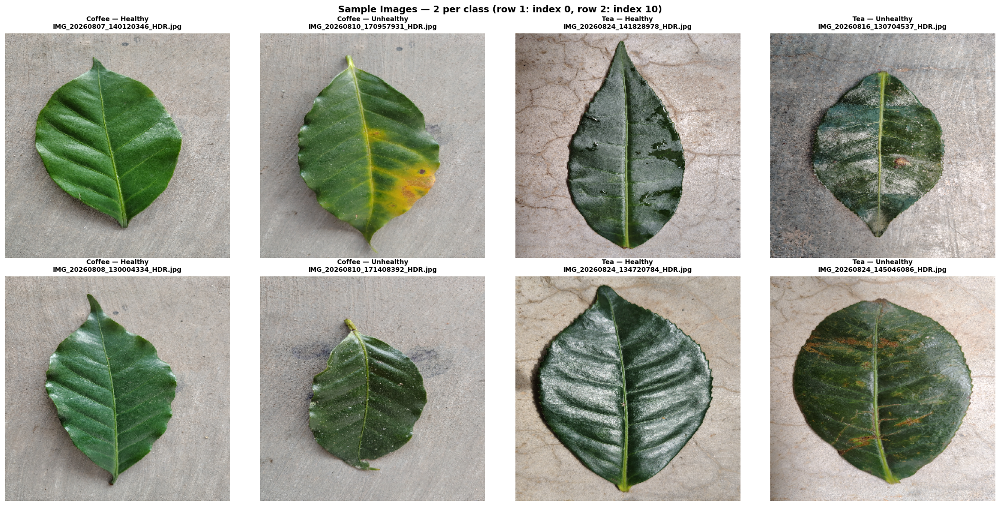

Saved: sample_images.png


In [3]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))

samples = [
    (coffee_path / 'HEALTHY',   'Coffee — Healthy'),
    (coffee_path / 'UNHEALTHY', 'Coffee — Unhealthy'),
    (tea_path    / 'HEALTHY',   'Tea — Healthy'),
    (tea_path    / 'UNHEALTHY', 'Tea — Unhealthy'),
]

for row in range(2):
    for col in range(4):
        idx = row * 0 + col if row == 0 else col
        cls_dir, label = samples[col]
        images = list(cls_dir.glob('*.jpg')) + list(cls_dir.glob('*.jpeg')) + list(cls_dir.glob('*.png'))
        img_path = images[row * 10]
        img = cv2.imread(str(img_path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (300, 300))
        axes[row][col].imshow(img)
        axes[row][col].set_title(f'{label}\n{img_path.name[:30]}', fontsize=9, fontweight='bold')
        axes[row][col].axis('off')

plt.suptitle('Sample Images — 2 per class (row 1: index 0, row 2: index 10)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/sample_images.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: sample_images.png")

# Class Distribution Chart

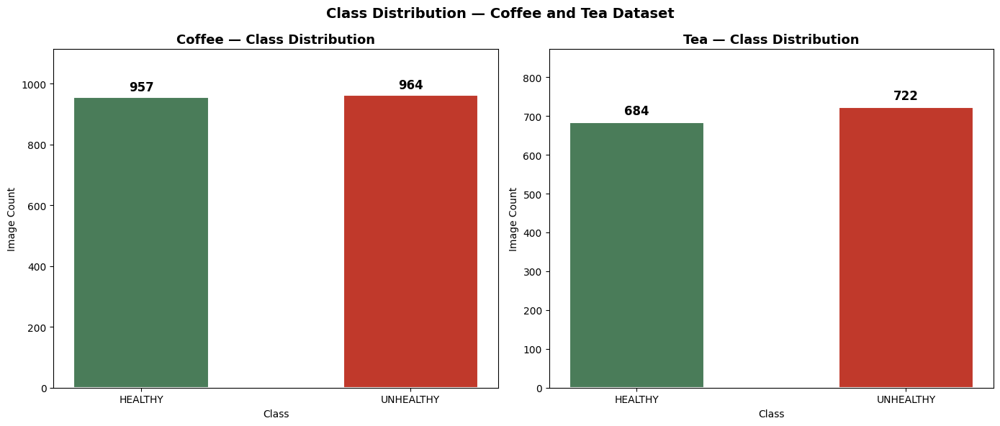

Overall dataset summary:
  Coffee : 1921 images
  Tea    : 1406 images
  Ratio  : 1.37x
Saved: class_distribution.png


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

colors_map = {'HEALTHY': '#4A7C59', 'UNHEALTHY': '#C0392B'}

for ax, (crop, counts) in zip(axes, [('Coffee', coffee_counts), ('Tea', tea_counts)]):
    bars = ax.bar(counts['class'], counts['count'],
                  color=[colors_map[c] for c in counts['class']],
                  width=0.5, edgecolor='white', linewidth=1.5)
    ax.set_title(f'{crop} — Class Distribution', fontsize=13, fontweight='bold')
    ax.set_xlabel('Class')
    ax.set_ylabel('Image Count')
    ax.set_ylim(0, max(counts['count']) + 150)
    for bar, val in zip(bars, counts['count']):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 20, str(val),
                ha='center', fontsize=12, fontweight='bold')

plt.suptitle('Class Distribution — Coffee and Tea Dataset', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print("Overall dataset summary:")
print(f"  Coffee : {957+964} images")
print(f"  Tea    : {684+722} images")
print(f"  Ratio  : {(957+964)/(684+722):.2f}x")
print("Saved: class_distribution.png")

# Image Size Distribution Analysis

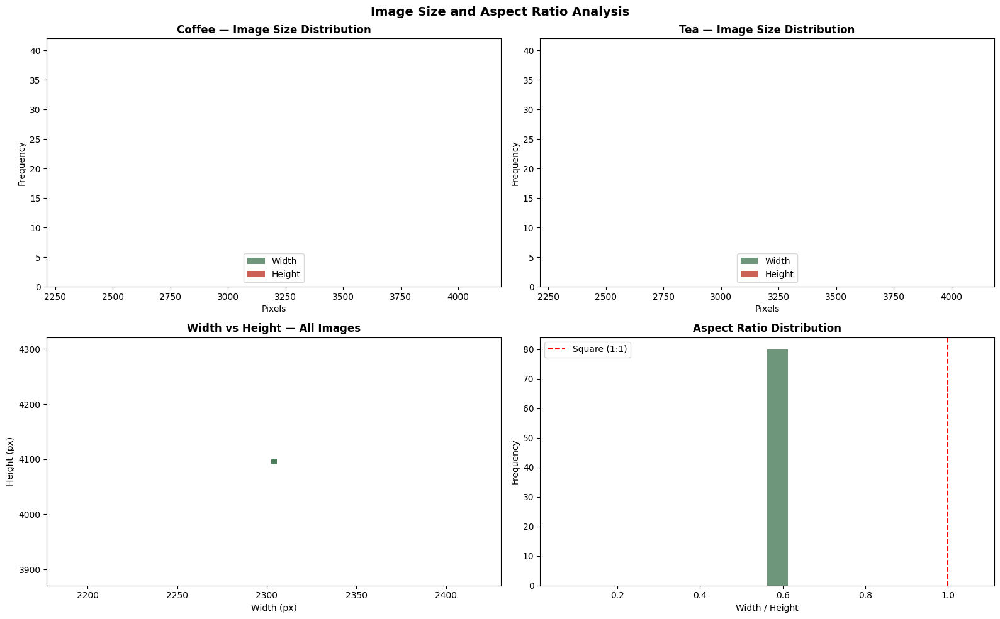

COFFEE IMAGE SIZES:
  Avg Width  : 2304px | Avg Height : 4096px
  Min        : 2304px | Max        : 4096px

TEA IMAGE SIZES:
  Avg Width  : 2304px | Avg Height : 4096px
  Min        : 2304px | Max        : 4096px

All images will be resized to 224x224 during training.
Saved: size_distribution.png


In [5]:
def sample_image_sizes(base_path, sample_per_class=20):
    widths, heights, labels = [], [], []
    for cls_dir in base_path.iterdir():
        if not cls_dir.is_dir():
            continue
        images = list(cls_dir.glob('*.jpg')) + list(cls_dir.glob('*.jpeg')) + list(cls_dir.glob('*.png'))
        for img_path in images[:sample_per_class]:
            img = cv2.imread(str(img_path))
            if img is not None:
                h, w = img.shape[:2]
                widths.append(w)
                heights.append(h)
                labels.append(cls_dir.name)
    return widths, heights, labels

coffee_w, coffee_h, coffee_l = sample_image_sizes(coffee_path)
tea_w,    tea_h,    tea_l    = sample_image_sizes(tea_path)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

axes[0, 0].hist(coffee_w, bins=20, color='#4A7C59', alpha=0.8, label='Width')
axes[0, 0].hist(coffee_h, bins=20, color='#C0392B', alpha=0.8, label='Height')
axes[0, 0].set_title('Coffee — Image Size Distribution', fontweight='bold')
axes[0, 0].set_xlabel('Pixels')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].legend()

axes[0, 1].hist(tea_w, bins=20, color='#4A7C59', alpha=0.8, label='Width')
axes[0, 1].hist(tea_h, bins=20, color='#C0392B', alpha=0.8, label='Height')
axes[0, 1].set_title('Tea — Image Size Distribution', fontweight='bold')
axes[0, 1].set_xlabel('Pixels')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].legend()

all_w = coffee_w + tea_w
all_h = coffee_h + tea_h
axes[1, 0].scatter(all_w, all_h, alpha=0.5, color='#4A7C59', s=30)
axes[1, 0].set_title('Width vs Height — All Images', fontweight='bold')
axes[1, 0].set_xlabel('Width (px)')
axes[1, 0].set_ylabel('Height (px)')

aspect_ratios = [w/h for w, h in zip(all_w, all_h)]
axes[1, 1].hist(aspect_ratios, bins=20, color='#4A7C59', alpha=0.8)
axes[1, 1].set_title('Aspect Ratio Distribution', fontweight='bold')
axes[1, 1].set_xlabel('Width / Height')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].axvline(x=1.0, color='red', linestyle='--', label='Square (1:1)')
axes[1, 1].legend()

plt.suptitle('Image Size and Aspect Ratio Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/size_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print("COFFEE IMAGE SIZES:")
print(f"  Avg Width  : {np.mean(coffee_w):.0f}px | Avg Height : {np.mean(coffee_h):.0f}px")
print(f"  Min        : {min(min(coffee_w), min(coffee_h))}px | Max        : {max(max(coffee_w), max(coffee_h))}px")

print("\nTEA IMAGE SIZES:")
print(f"  Avg Width  : {np.mean(tea_w):.0f}px | Avg Height : {np.mean(tea_h):.0f}px")
print(f"  Min        : {min(min(tea_w), min(tea_h))}px | Max        : {max(max(tea_w), max(tea_h))}px")

print(f"\nAll images will be resized to 224x224 during training.")
print("Saved: size_distribution.png")

# Check Image Channels and Corruption

In [6]:
def check_image_quality(base_path, crop_name):
    issues = []
    total = 0
    channel_counts = defaultdict(int)

    for cls_dir in base_path.iterdir():
        if not cls_dir.is_dir():
            continue
        images = list(cls_dir.glob('*.jpg')) + list(cls_dir.glob('*.jpeg')) + list(cls_dir.glob('*.png'))
        for img_path in images:
            total += 1
            img = cv2.imread(str(img_path))
            if img is None:
                issues.append({'file': img_path.name, 'class': cls_dir.name, 'issue': 'corrupted/unreadable'})
                continue
            channels = img.shape[2] if len(img.shape) == 3 else 1
            channel_counts[channels] += 1
            h, w = img.shape[:2]
            if h < 100 or w < 100:
                issues.append({'file': img_path.name, 'class': cls_dir.name, 'issue': f'too small {w}x{h}'})

    print(f"\n{crop_name} IMAGE QUALITY REPORT:")
    print(f"  Total images checked : {total}")
    print(f"  Channel distribution : {dict(channel_counts)}")
    print(f"  Issues found         : {len(issues)}")
    if issues:
        for issue in issues[:10]:
            print(f"    {issue['class']} | {issue['file']} | {issue['issue']}")
    return issues

coffee_issues = check_image_quality(coffee_path, 'COFFEE')
tea_issues    = check_image_quality(tea_path, 'TEA')

total_issues = len(coffee_issues) + len(tea_issues)
print(f"\nTotal issues across both crops: {total_issues}")
if total_issues == 0:
    print("All images are readable and valid.")


COFFEE IMAGE QUALITY REPORT:
  Total images checked : 1921
  Channel distribution : {3: 1921}
  Issues found         : 0

TEA IMAGE QUALITY REPORT:
  Total images checked : 1406
  Channel distribution : {3: 1406}
  Issues found         : 0

Total issues across both crops: 0
All images are readable and valid.


# Visual Quality Check — Spot Mislabeled Images in Healthy Folders

Showing 16 random samples from each HEALTHY folder for visual inspection.
Look for any images showing spots, yellowing, browning, or disease symptoms.

Coffee Healthy: 957 images total — inspect rows 1 and 2

Tea Healthy: 684 images total — inspect rows 3 and 4


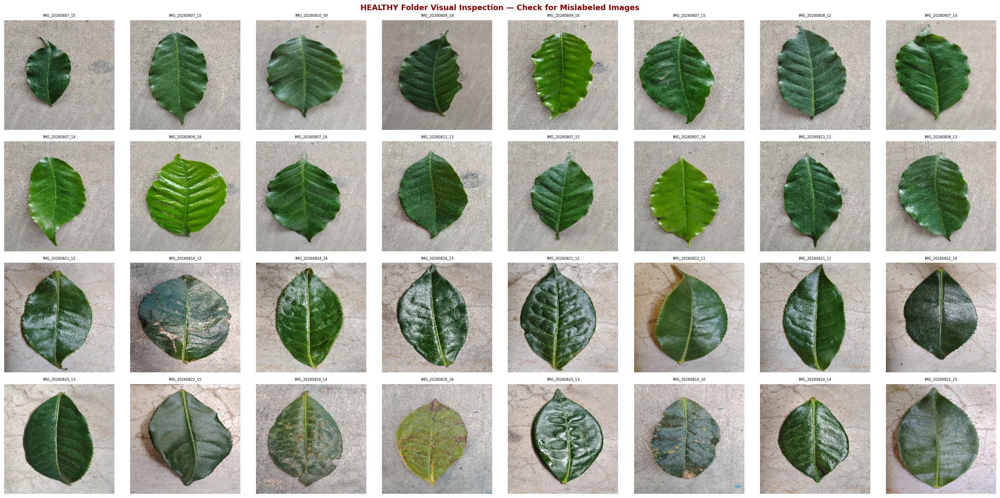


Saved: healthy_visual_inspection.png


In [7]:
fig, axes = plt.subplots(4, 8, figsize=(24, 12))

healthy_paths = {
    'Coffee Healthy': list((coffee_path / 'HEALTHY').glob('*.jpg')) + 
                      list((coffee_path / 'HEALTHY').glob('*.jpeg')),
    'Tea Healthy':    list((tea_path / 'HEALTHY').glob('*.jpg')) + 
                      list((tea_path / 'HEALTHY').glob('*.jpeg')),
}

print("Showing 16 random samples from each HEALTHY folder for visual inspection.")
print("Look for any images showing spots, yellowing, browning, or disease symptoms.")
print("=" * 70)

import random
random.seed(42)

for row_offset, (label, img_list) in enumerate(healthy_paths.items()):
    sampled = random.sample(img_list, min(16, len(img_list)))
    for col_idx, img_path in enumerate(sampled):
        img = cv2.imread(str(img_path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (200, 200))
        ax = axes[row_offset * 2 + (col_idx // 8)][col_idx % 8]
        ax.imshow(img)
        ax.set_title(f'{img_path.name[:15]}', fontsize=6)
        ax.axis('off')

    print(f"\n{label}: {len(img_list)} images total — inspect rows {row_offset*2+1} and {row_offset*2+2}")

plt.suptitle('HEALTHY Folder Visual Inspection — Check for Mislabeled Images',
             fontsize=13, fontweight='bold', color='darkred')
plt.tight_layout()
plt.savefig('/kaggle/working/healthy_visual_inspection.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nSaved: healthy_visual_inspection.png")

# Extended Healthy Folder Inspection — More Samples

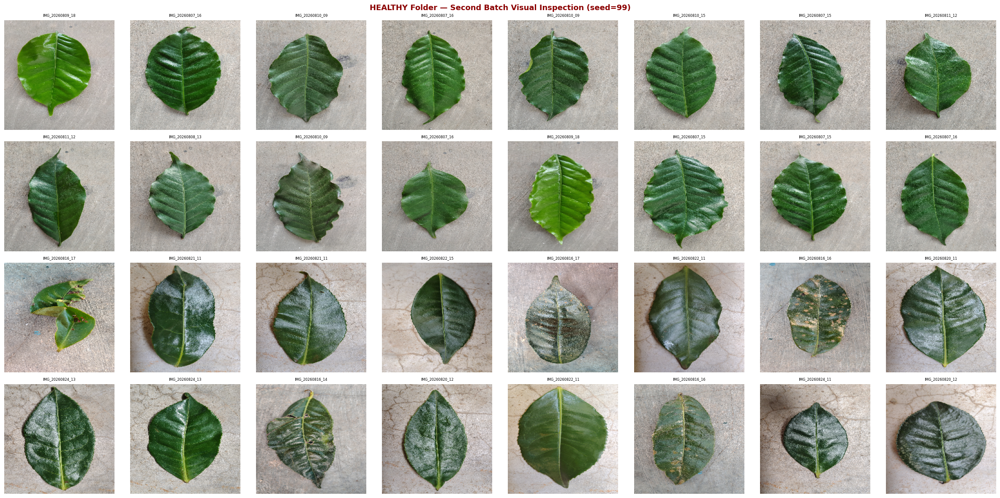

Saved: healthy_inspection_batch2.png


In [8]:
fig, axes = plt.subplots(4, 8, figsize=(24, 12))

random.seed(99)

for row_offset, (label, img_list) in enumerate(healthy_paths.items()):
    sampled = random.sample(img_list, min(16, len(img_list)))
    for col_idx, img_path in enumerate(sampled):
        img = cv2.imread(str(img_path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (200, 200))
        ax = axes[row_offset * 2 + (col_idx // 8)][col_idx % 8]
        ax.imshow(img)
        ax.set_title(f'{img_path.name[:15]}', fontsize=6)
        ax.axis('off')

plt.suptitle('HEALTHY Folder — Second Batch Visual Inspection (seed=99)',
             fontsize=13, fontweight='bold', color='darkred')
plt.tight_layout()
plt.savefig('/kaggle/working/healthy_inspection_batch2.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: healthy_inspection_batch2.png")

# Automated Mislabel Detection Using Color Analysis

In [9]:
def detect_suspicious_healthy(cls_path, crop_name, threshold_yellow=0.08, threshold_brown=0.05):
    suspicious = []
    images = list(cls_path.glob('*.jpg')) + list(cls_path.glob('*.jpeg')) + list(cls_path.glob('*.png'))

    for img_path in images:
        img = cv2.imread(str(img_path))
        if img is None:
            continue
        img_resized = cv2.resize(img, (256, 256))
        hsv = cv2.cvtColor(img_resized, cv2.COLOR_BGR2HSV)
        total_pixels = 256 * 256

        yellow_mask = cv2.inRange(hsv, np.array([20, 80, 150]), np.array([35, 255, 255]))
        brown_mask  = cv2.inRange(hsv, np.array([0,  40,  30]),  np.array([18, 255, 170]))
        gray_mask   = cv2.inRange(hsv, np.array([0,  0,   55]),  np.array([180, 45, 160]))

        yellow_ratio = np.sum(yellow_mask > 0) / total_pixels
        brown_ratio  = np.sum(brown_mask  > 0) / total_pixels
        gray_ratio   = np.sum(gray_mask   > 0) / total_pixels

        if yellow_ratio > threshold_yellow or brown_ratio > threshold_brown:
            suspicious.append({
                'file':         img_path.name,
                'path':         str(img_path),
                'yellow_ratio': round(yellow_ratio, 4),
                'brown_ratio':  round(brown_ratio,  4),
                'gray_ratio':   round(gray_ratio,   4),
            })

    print(f"\n{crop_name} HEALTHY — Suspicious images found: {len(suspicious)} / {len(images)}")
    if suspicious:
        df = pd.DataFrame(suspicious).sort_values('brown_ratio', ascending=False)
        print(df[['file', 'yellow_ratio', 'brown_ratio', 'gray_ratio']].head(20).to_string(index=False))
    return suspicious

coffee_suspicious = detect_suspicious_healthy(coffee_path / 'HEALTHY', 'COFFEE')
tea_suspicious    = detect_suspicious_healthy(tea_path    / 'HEALTHY', 'TEA')

print(f"\nTotal suspicious images: {len(coffee_suspicious) + len(tea_suspicious)}")
print("These are candidates for removal or relabeling before training.")


COFFEE HEALTHY — Suspicious images found: 0 / 957

TEA HEALTHY — Suspicious images found: 285 / 684
                          file  yellow_ratio  brown_ratio  gray_ratio
IMG_20260822_111523464_HDR.jpg        0.0000       0.2160      0.1428
IMG_20260824_141400604_HDR.jpg        0.0001       0.1910      0.1527
IMG_20260822_111404458_HDR.jpg        0.0002       0.1742      0.0871
IMG_20260822_110317013_HDR.jpg        0.0010       0.1712      0.1247
IMG_20260824_113423487_HDR.jpg        0.0014       0.1665      0.1558
IMG_20260822_111733804_HDR.jpg        0.0000       0.1585      0.2058
IMG_20260820_114015367_HDR.jpg        0.0034       0.1573      0.0640
IMG_20260824_143917301_HDR.jpg        0.0010       0.1558      0.1758
IMG_20260822_155611838_HDR.jpg        0.0012       0.1539      0.2102
IMG_20260822_111006686_HDR.jpg        0.0000       0.1526      0.1693
IMG_20260822_113947575_HDR.jpg        0.0000       0.1460      0.1454
IMG_20260824_113337292_HDR.jpg        0.0025       0.1401  

# Visualize Top Suspicious Tea Healthy Images

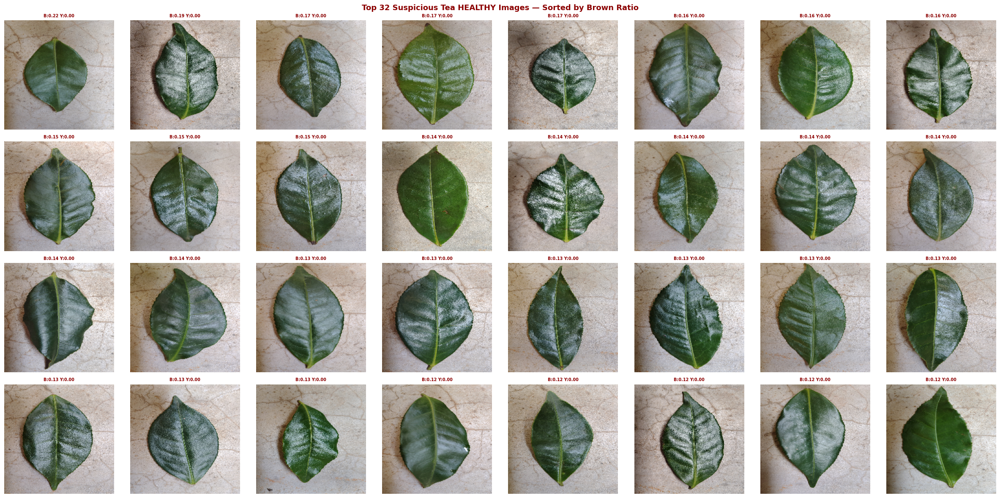

Saved: suspicious_tea_healthy.png


In [10]:
tea_susp_df = pd.DataFrame(tea_suspicious).sort_values('brown_ratio', ascending=False)

fig, axes = plt.subplots(4, 8, figsize=(24, 12))
axes = axes.flatten()

for i, (_, row) in enumerate(tea_susp_df.head(32).iterrows()):
    img = cv2.imread(row['path'])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (200, 200))
    axes[i].imshow(img)
    axes[i].set_title(
        f"B:{row['brown_ratio']:.2f} Y:{row['yellow_ratio']:.2f}",
        fontsize=7, color='darkred', fontweight='bold'
    )
    axes[i].axis('off')

plt.suptitle('Top 32 Suspicious Tea HEALTHY Images — Sorted by Brown Ratio',
             fontsize=13, fontweight='bold', color='darkred')
plt.tight_layout()
plt.savefig('/kaggle/working/suspicious_tea_healthy.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: suspicious_tea_healthy.png")

# Recalibrate Threshold and Final Mislabel Detection

In [11]:
def detect_mislabeled_final(cls_path, crop_name, 
                             yellow_threshold=0.12, 
                             brown_threshold=0.25,
                             require_both=False):
    suspicious = []
    images = list(cls_path.glob('*.jpg')) + \
             list(cls_path.glob('*.jpeg')) + \
             list(cls_path.glob('*.png'))

    for img_path in images:
        img = cv2.imread(str(img_path))
        if img is None:
            continue
        img_resized = cv2.resize(img, (256, 256))
        hsv = cv2.cvtColor(img_resized, cv2.COLOR_BGR2HSV)
        total_pixels = 256 * 256

        yellow_mask = cv2.inRange(hsv,
                                  np.array([18, 80, 120]),
                                  np.array([35, 255, 255]))
        brown_mask  = cv2.inRange(hsv,
                                  np.array([0,  60,  40]),
                                  np.array([15, 255, 150]))
        black_mask  = cv2.inRange(hsv,
                                  np.array([0,  0,   0]),
                                  np.array([180, 80, 45]))

        yellow_ratio = np.sum(yellow_mask > 0) / total_pixels
        brown_ratio  = np.sum(brown_mask  > 0) / total_pixels
        black_ratio  = np.sum(black_mask  > 0) / total_pixels

        flag_yellow = yellow_ratio > yellow_threshold
        flag_brown  = brown_ratio  > brown_threshold
        flag_black  = black_ratio  > 0.10

        is_suspicious = flag_yellow or flag_brown or flag_black

        if is_suspicious:
            suspicious.append({
                'file':         img_path.name,
                'path':         str(img_path),
                'yellow_ratio': round(yellow_ratio, 4),
                'brown_ratio':  round(brown_ratio,  4),
                'black_ratio':  round(black_ratio,  4),
                'reason':       ('yellow ' if flag_yellow else '') +
                                ('brown '  if flag_brown  else '') +
                                ('black'   if flag_black  else '')
            })

    df = pd.DataFrame(suspicious) if suspicious else pd.DataFrame()
    print(f"\n{crop_name} HEALTHY — Mislabeled candidates: {len(suspicious)} / {len(images)}")
    if not df.empty:
        print(df[['file','yellow_ratio','brown_ratio','black_ratio','reason']]\
              .sort_values('brown_ratio', ascending=False)\
              .head(30).to_string(index=False))
    return suspicious

coffee_mislabeled = detect_mislabeled_final(coffee_path / 'HEALTHY', 'COFFEE')
tea_mislabeled    = detect_mislabeled_final(tea_path    / 'HEALTHY', 'TEA')

print(f"\nFinal mislabel count — Coffee: {len(coffee_mislabeled)} | Tea: {len(tea_mislabeled)}")
print(f"Total to exclude from training: {len(coffee_mislabeled) + len(tea_mislabeled)}")


COFFEE HEALTHY — Mislabeled candidates: 0 / 957

TEA HEALTHY — Mislabeled candidates: 1 / 684
                          file  yellow_ratio  brown_ratio  black_ratio  reason
IMG_20260816_163021630_HDR.jpg        0.1627       0.0114          0.0 yellow 

Final mislabel count — Coffee: 0 | Tea: 1
Total to exclude from training: 1


# Visualize the 1 Suspicious Tea Image

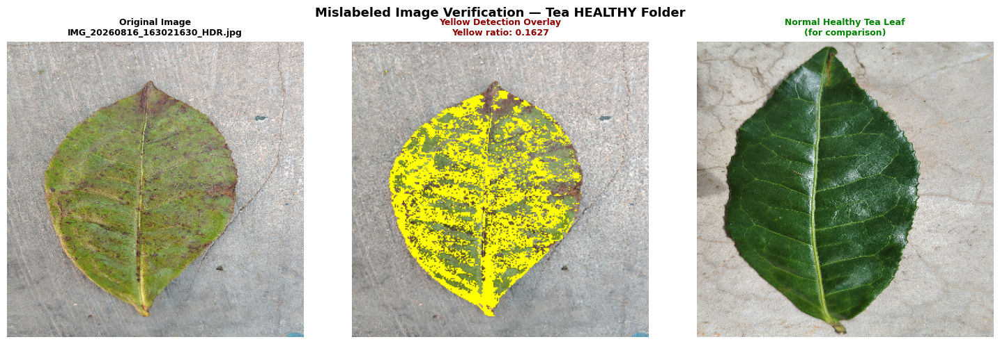

File to exclude: IMG_20260816_163021630_HDR.jpg
Yellow ratio   : 0.1627
Brown ratio    : 0.0114
This image will be excluded from training data.


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

suspicious_path = tea_mislabeled[0]['path']
img_bgr = cv2.imread(suspicious_path)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_resized = cv2.resize(img_bgr, (256, 256))
hsv = cv2.cvtColor(img_resized, cv2.COLOR_BGR2HSV)

yellow_mask = cv2.inRange(hsv, np.array([18, 80, 120]), np.array([35, 255, 255]))

axes[0].imshow(cv2.resize(img_rgb, (400, 400)))
axes[0].set_title('Original Image\n' + tea_mislabeled[0]['file'], fontsize=9, fontweight='bold')
axes[0].axis('off')

overlay = cv2.resize(img_rgb, (256, 256)).copy()
overlay[yellow_mask > 0] = [255, 255, 0]
axes[1].imshow(overlay)
axes[1].set_title(f"Yellow Detection Overlay\nYellow ratio: {tea_mislabeled[0]['yellow_ratio']:.4f}",
                  fontsize=9, fontweight='bold', color='darkred')
axes[1].axis('off')

compare_path = list((tea_path / 'HEALTHY').glob('*.jpg'))[5]
compare_img = cv2.imread(str(compare_path))
compare_img = cv2.cvtColor(compare_img, cv2.COLOR_BGR2RGB)
axes[2].imshow(cv2.resize(compare_img, (400, 400)))
axes[2].set_title('Normal Healthy Tea Leaf\n(for comparison)', fontsize=9, fontweight='bold', color='green')
axes[2].axis('off')

plt.suptitle('Mislabeled Image Verification — Tea HEALTHY Folder',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/mislabeled_verification.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"File to exclude: {tea_mislabeled[0]['file']}")
print(f"Yellow ratio   : {tea_mislabeled[0]['yellow_ratio']}")
print(f"Brown ratio    : {tea_mislabeled[0]['brown_ratio']}")
print("This image will be excluded from training data.")

# Build Final Clean DataFrames

In [13]:
EXCLUDE_FILES = {
    'IMG_20260816_163021630_HDR.jpg'
}

records = []

for cls_dir in coffee_path.iterdir():
    if not cls_dir.is_dir():
        continue
    label = cls_dir.name.upper()
    images = list(cls_dir.glob('*.jpg')) + \
             list(cls_dir.glob('*.jpeg')) + \
             list(cls_dir.glob('*.png'))
    for img_path in images:
        if img_path.name in EXCLUDE_FILES:
            continue
        records.append({
            'path':       str(img_path),
            'crop':       'coffee',
            'health':     'healthy' if label == 'HEALTHY' else 'unhealthy',
            'source_dir': label
        })

for cls_dir in tea_path.iterdir():
    if not cls_dir.is_dir():
        continue
    label = cls_dir.name.upper()
    images = list(cls_dir.glob('*.jpg')) + \
             list(cls_dir.glob('*.jpeg')) + \
             list(cls_dir.glob('*.png'))
    for img_path in images:
        if img_path.name in EXCLUDE_FILES:
            continue
        records.append({
            'path':       str(img_path),
            'crop':       'tea',
            'health':     'healthy' if label == 'HEALTHY' else 'unhealthy',
            'source_dir': label
        })

df = pd.DataFrame(records)

print("FINAL CLEAN DATASET:")
print(f"  Total images     : {len(df)}")
print(f"  Excluded         : 1 (mislabeled)")
print(f"\nCrop distribution:")
print(df['crop'].value_counts().to_string())
print(f"\nHealth distribution:")
print(df['health'].value_counts().to_string())
print(f"\nCrop x Health breakdown:")
print(df.groupby(['crop', 'health']).size().to_string())

df.to_csv('/kaggle/working/dataset.csv', index=False)
print("\nSaved: dataset.csv")

FINAL CLEAN DATASET:
  Total images     : 3325
  Excluded         : 1 (mislabeled)

Crop distribution:
crop
coffee    1921
tea       1404

Health distribution:
health
unhealthy    1685
healthy      1640

Crop x Health breakdown:
crop    health   
coffee  healthy      957
        unhealthy    964
tea     healthy      683
        unhealthy    721

Saved: dataset.csv


# EDA — Crop and Health Distribution Charts

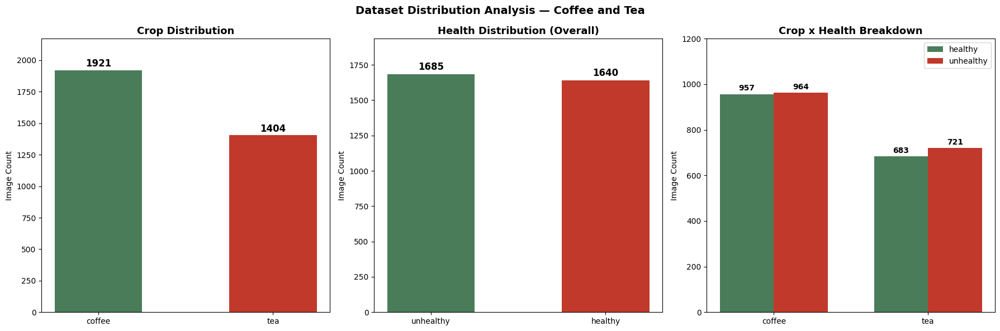

Saved: dataset_distribution.png


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

crop_counts = df['crop'].value_counts()
colors_crop = ['#4A7C59', '#C0392B']
bars = axes[0].bar(crop_counts.index, crop_counts.values, color=colors_crop, width=0.5)
axes[0].set_title('Crop Distribution', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Image Count')
axes[0].set_ylim(0, max(crop_counts.values) + 250)
for bar, val in zip(bars, crop_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 30, str(val),
                 ha='center', fontsize=12, fontweight='bold')

health_counts = df['health'].value_counts()
colors_health = ['#4A7C59', '#C0392B']
bars2 = axes[1].bar(health_counts.index, health_counts.values, color=colors_health, width=0.5)
axes[1].set_title('Health Distribution (Overall)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Image Count')
axes[1].set_ylim(0, max(health_counts.values) + 250)
for bar, val in zip(bars2, health_counts.values):
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 30, str(val),
                 ha='center', fontsize=12, fontweight='bold')

breakdown = df.groupby(['crop', 'health']).size().reset_index(name='count')
crops  = breakdown['crop'].unique()
x      = np.arange(len(crops))
width  = 0.35
health_labels = ['healthy', 'unhealthy']
colors_breakdown = ['#4A7C59', '#C0392B']
for i, (hlabel, color) in enumerate(zip(health_labels, colors_breakdown)):
    vals = [breakdown[(breakdown['crop']==c) & (breakdown['health']==hlabel)]['count'].values[0]
            for c in crops]
    bars3 = axes[2].bar(x + i * width, vals, width, label=hlabel, color=color)
    for bar, val in zip(bars3, vals):
        axes[2].text(bar.get_x() + bar.get_width()/2,
                     bar.get_height() + 15, str(val),
                     ha='center', fontsize=10, fontweight='bold')

axes[2].set_title('Crop x Health Breakdown', fontsize=13, fontweight='bold')
axes[2].set_ylabel('Image Count')
axes[2].set_xticks(x + width / 2)
axes[2].set_xticklabels(crops)
axes[2].legend()
axes[2].set_ylim(0, 1200)

plt.suptitle('Dataset Distribution Analysis — Coffee and Tea', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/dataset_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: dataset_distribution.png")

# Compute Class Weights for Both Models

In [15]:
from sklearn.utils.class_weight import compute_class_weight

CROP_CLASSES   = ['coffee', 'tea']
HEALTH_CLASSES = ['healthy', 'unhealthy']

CROP_TO_IDX   = {c: i for i, c in enumerate(CROP_CLASSES)}
HEALTH_TO_IDX = {c: i for i, c in enumerate(HEALTH_CLASSES)}

crop_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array(CROP_CLASSES),
    y=df['crop'].values
)

health_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array(HEALTH_CLASSES),
    y=df['health'].values
)

crop_weight_dict   = dict(zip(CROP_CLASSES,   crop_weights))
health_weight_dict = dict(zip(HEALTH_CLASSES, health_weights))

print("CROP CLASS WEIGHTS:")
for cls, w in crop_weight_dict.items():
    print(f"  {cls:<12} : {w:.4f}")

print("\nHEALTH CLASS WEIGHTS:")
for cls, w in health_weight_dict.items():
    print(f"  {cls:<12} : {w:.4f}")

crop_weight_list   = [crop_weight_dict[c]   for c in CROP_CLASSES]
health_weight_list = [health_weight_dict[c] for c in HEALTH_CLASSES]

print(f"\nCrop weight tensor   : {[round(w, 4) for w in crop_weight_list]}")
print(f"Health weight tensor : {[round(w, 4) for w in health_weight_list]}")

np.save('/kaggle/working/crop_class_weights.npy',   np.array(crop_weight_list))
np.save('/kaggle/working/health_class_weights.npy', np.array(health_weight_list))
print("\nSaved: crop_class_weights.npy and health_class_weights.npy")

CROP CLASS WEIGHTS:
  coffee       : 0.8654
  tea          : 1.1841

HEALTH CLASS WEIGHTS:
  healthy      : 1.0137
  unhealthy    : 0.9866

Crop weight tensor   : [np.float64(0.8654), np.float64(1.1841)]
Health weight tensor : [np.float64(1.0137), np.float64(0.9866)]

Saved: crop_class_weights.npy and health_class_weights.npy


# Train-Val-Test Split

In [16]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df, test_size=0.2, random_state=42,
    stratify=df[['crop', 'health']].apply(lambda x: x['crop'] + '_' + x['health'], axis=1)
)

val_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=42,
    stratify=temp_df[['crop', 'health']].apply(lambda x: x['crop'] + '_' + x['health'], axis=1)
)

print("TRAIN / VAL / TEST SPLIT:")
print(f"  Train : {len(train_df)} images")
print(f"  Val   : {len(val_df)} images")
print(f"  Test  : {len(test_df)} images")

print(f"\nTrain crop distribution:")
print(train_df['crop'].value_counts().to_string())
print(f"\nTrain health distribution:")
print(train_df['health'].value_counts().to_string())

print(f"\nVal crop distribution:")
print(val_df['crop'].value_counts().to_string())
print(f"\nTest crop distribution:")
print(test_df['crop'].value_counts().to_string())

train_df.to_csv('/kaggle/working/train.csv', index=False)
val_df.to_csv('/kaggle/working/val.csv',   index=False)
test_df.to_csv('/kaggle/working/test.csv',  index=False)
print("\nSaved: train.csv, val.csv, test.csv")

TRAIN / VAL / TEST SPLIT:
  Train : 2660 images
  Val   : 332 images
  Test  : 333 images

Train crop distribution:
crop
coffee    1537
tea       1123

Train health distribution:
health
unhealthy    1348
healthy      1312

Val crop distribution:
crop
coffee    191
tea       141

Test crop distribution:
crop
coffee    193
tea       140

Saved: train.csv, val.csv, test.csv


# Build PyTorch Datasets and Dataloaders

In [17]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class LeafDataset(Dataset):
    def __init__(self, df, label_col, label_to_idx, transform=None):
        self.df           = df.reset_index(drop=True)
        self.label_col    = label_col
        self.label_to_idx = label_to_idx
        self.transform    = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        img   = Image.open(row['path']).convert('RGB')
        if self.transform:
            img = self.transform(img)
        label = self.label_to_idx[row[self.label_col]]
        return img, label

crop_train_ds = LeafDataset(train_df, 'crop',   CROP_TO_IDX,   train_transforms)
crop_val_ds   = LeafDataset(val_df,   'crop',   CROP_TO_IDX,   val_transforms)
crop_test_ds  = LeafDataset(test_df,  'crop',   CROP_TO_IDX,   val_transforms)

health_train_ds = LeafDataset(train_df, 'health', HEALTH_TO_IDX, train_transforms)
health_val_ds   = LeafDataset(val_df,   'health', HEALTH_TO_IDX, val_transforms)
health_test_ds  = LeafDataset(test_df,  'health', HEALTH_TO_IDX, val_transforms)

BATCH_SIZE = 32

crop_train_loader   = DataLoader(crop_train_ds,   batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
crop_val_loader     = DataLoader(crop_val_ds,     batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
crop_test_loader    = DataLoader(crop_test_ds,    batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

health_train_loader = DataLoader(health_train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
health_val_loader   = DataLoader(health_val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
health_test_loader  = DataLoader(health_test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
print(f"\nCrop model dataloaders:")
print(f"  Train batches : {len(crop_train_loader)}")
print(f"  Val batches   : {len(crop_val_loader)}")
print(f"  Test batches  : {len(crop_test_loader)}")
print(f"\nHealth model dataloaders:")
print(f"  Train batches : {len(health_train_loader)}")
print(f"  Val batches   : {len(health_val_loader)}")
print(f"  Test batches  : {len(health_test_loader)}")

imgs, labels = next(iter(crop_train_loader))
print(f"\nSample crop batch   — Images: {imgs.shape} | Labels: {labels.shape}")
imgs, labels = next(iter(health_train_loader))
print(f"Sample health batch — Images: {imgs.shape} | Labels: {labels.shape}")

Device: cuda

Crop model dataloaders:
  Train batches : 84
  Val batches   : 11
  Test batches  : 11

Health model dataloaders:
  Train batches : 84
  Val batches   : 11
  Test batches  : 11

Sample crop batch   — Images: torch.Size([32, 3, 224, 224]) | Labels: torch.Size([32])
Sample health batch — Images: torch.Size([32, 3, 224, 224]) | Labels: torch.Size([32])


# Build Crop Model — EfficientNet-B4

In [25]:
class CropModel(nn.Module):
    def __init__(self, num_classes=2):
        super(CropModel, self).__init__()
        self.backbone = models.efficientnet_b4(weights=None)
        in_features = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Identity()
        self.classifier = nn.Sequential(
            nn.BatchNorm1d(in_features),
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.backbone(x)
        x = self.classifier(x)
        return x

crop_model = CropModel(num_classes=len(CROP_CLASSES)).to(device)

crop_weight_tensor = torch.tensor(crop_weight_list, dtype=torch.float32).to(device)
criterion_crop     = nn.CrossEntropyLoss(weight=crop_weight_tensor)
optimizer_crop     = torch.optim.AdamW(crop_model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler_crop     = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_crop, T_max=10, eta_min=1e-6
)

total_params     = sum(p.numel() for p in crop_model.parameters())
trainable_params = sum(p.numel() for p in crop_model.parameters() if p.requires_grad)
print(f"Device               : {device}")
print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")
print(f"Pretrained weights   : None — training from scratch")
print(f"Num classes          : {len(CROP_CLASSES)} — {CROP_CLASSES}")

Device               : cuda
Total parameters     : 18,602,058
Trainable parameters : 18,602,058
Pretrained weights   : None — training from scratch
Num classes          : 2 — ['coffee', 'tea']


# Train Crop Model

In [27]:
from tqdm import tqdm

NUM_EPOCHS = 10
best_val_acc = 0.0
best_epoch = 0
train_losses, val_losses = [], []
train_accs, val_accs = [], []
early_stop_patience = 5
no_improve_count = 0

print(f"Starting Crop Model Training — {NUM_EPOCHS} epochs (no pretrained weights)")
print("-" * 90)

for epoch in range(1, NUM_EPOCHS + 1):
    start = time.time()

    crop_model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0

    train_bar = tqdm(crop_train_loader, desc=f"Epoch {epoch}/{NUM_EPOCHS} [Train]", leave=False)
    for imgs, labels in train_bar:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer_crop.zero_grad()
        outputs = crop_model(imgs)
        loss = criterion_crop(outputs, labels)
        loss.backward()
        optimizer_crop.step()
        train_loss += loss.item() * imgs.size(0)
        preds = outputs.argmax(dim=1)
        train_correct += (preds == labels).sum().item()
        train_total += imgs.size(0)
        train_bar.set_postfix({
            'loss': f"{train_loss/train_total:.4f}",
            'acc':  f"{train_correct/train_total*100:.2f}%"
        })

    crop_model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0

    val_bar = tqdm(crop_val_loader, desc=f"Epoch {epoch}/{NUM_EPOCHS} [Val]  ", leave=False)
    with torch.no_grad():
        for imgs, labels in val_bar:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = crop_model(imgs)
            loss = criterion_crop(outputs, labels)
            val_loss += loss.item() * imgs.size(0)
            preds = outputs.argmax(dim=1)
            val_correct += (preds == labels).sum().item()
            val_total += imgs.size(0)
            val_bar.set_postfix({
                'loss': f"{val_loss/val_total:.4f}",
                'acc':  f"{val_correct/val_total*100:.2f}%"
            })

    avg_train_loss = train_loss / train_total
    avg_val_loss   = val_loss   / val_total
    avg_train_acc  = train_correct / train_total * 100
    avg_val_acc    = val_correct   / val_total   * 100
    current_lr     = optimizer_crop.param_groups[0]['lr']
    elapsed        = time.time() - start

    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    train_accs.append(avg_train_acc)
    val_accs.append(avg_val_acc)

    scheduler_crop.step()

    if avg_val_acc > best_val_acc:
        best_val_acc = avg_val_acc
        best_epoch = epoch
        torch.save(crop_model.state_dict(), '/kaggle/working/crop_model_best.pth')
        flag = 'SAVED'
        no_improve_count = 0
    else:
        flag = ''
        no_improve_count += 1

    print(f"Epoch {epoch:>2}/{NUM_EPOCHS} | "
          f"Train Loss: {avg_train_loss:.4f} | Train Acc: {avg_train_acc:.2f}% | "
          f"Val Loss: {avg_val_loss:.4f} | Val Acc: {avg_val_acc:.2f}% | "
          f"LR: {current_lr:.6f} | Time: {elapsed:.1f}s  {flag}")

    if no_improve_count >= early_stop_patience:
        print(f"\nEarly stopping at epoch {epoch} — no improvement for {early_stop_patience} epochs")
        break

print(f"\nBest Val Accuracy : {best_val_acc:.2f}% at epoch {best_epoch}")
print(f"Model saved to    : /kaggle/working/crop_model_best.pth")

Starting Crop Model Training — 10 epochs (no pretrained weights)
------------------------------------------------------------------------------------------


Epoch  1/10 | Train Loss: 0.6985 | Train Acc: 56.02% | Val Loss: 0.6606 | Val Acc: 64.46% | LR: 0.000100 | Time: 199.8s  SAVED


Epoch  2/10 | Train Loss: 0.4784 | Train Acc: 77.97% | Val Loss: 0.1954 | Val Acc: 92.77% | LR: 0.000098 | Time: 208.3s  SAVED


Epoch  3/10 | Train Loss: 0.3897 | Train Acc: 83.65% | Val Loss: 0.2152 | Val Acc: 92.17% | LR: 0.000091 | Time: 203.6s  


Epoch  4/10 | Train Loss: 0.3159 | Train Acc: 86.20% | Val Loss: 0.1736 | Val Acc: 92.47% | LR: 0.000080 | Time: 208.6s  


Epoch  5/10 | Train Loss: 0.2501 | Train Acc: 90.19% | Val Loss: 0.1876 | Val Acc: 91.57% | LR: 0.000066 | Time: 204.2s  


Epoch  6/10 | Train Loss: 0.2123 | Train Acc: 92.07% | Val Loss: 0.0646 | Val Acc: 97.89% | LR: 0.000051 | Time: 201.8s  SAVED


Epoch  7/10 | Train Loss: 0.1707 | Train Acc: 93.35% | Val Loss: 0.0332 | Val Acc: 99.40% | LR: 0.000035 | Time: 203.3s  SAVED


Epoch  8/10 | Train Loss: 0.1677 | Train Acc: 93.20% | Val Loss: 0.0472 | Val Acc: 98.49% | LR: 0.000021 | Time: 202.6s  


Epoch  9/10 | Train Loss: 0.1679 | Train Acc: 93.91% | Val Loss: 0.0356 | Val Acc: 98.80% | LR: 0.000010 | Time: 207.1s  


Epoch 10/10 | Train Loss: 0.1512 | Train Acc: 94.21% | Val Loss: 0.0394 | Val Acc: 98.49% | LR: 0.000003 | Time: 217.0s  

Best Val Accuracy : 99.40% at epoch 7
Model saved to    : /kaggle/working/crop_model_best.pth


In [28]:
print(f"Best Val Accuracy : {best_val_acc:.2f}% at epoch {best_epoch}")
print(f"Model file exists : {Path('/kaggle/working/crop_model_best.pth').exists()}")
print(f"Model file size   : {Path('/kaggle/working/crop_model_best.pth').stat().st_size / 1e6:.1f} MB")

Best Val Accuracy : 99.40% at epoch 7
Model file exists : True
Model file size   : 75.2 MB


In [29]:
from sklearn.metrics import classification_report, confusion_matrix

crop_model.load_state_dict(torch.load('/kaggle/working/crop_model_best.pth'))
crop_model.eval()

all_preds, all_labels, all_probs = [], [], []

with torch.no_grad():
    for imgs, labels in crop_test_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = crop_model(imgs)
        probs   = torch.softmax(outputs, dim=1)
        preds   = outputs.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)
all_probs  = np.array(all_probs)

test_acc = (all_preds == all_labels).mean() * 100
print(f"Crop Model Test Accuracy: {test_acc:.2f}%")
print(f"\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=CROP_CLASSES, digits=4))

Crop Model Test Accuracy: 97.90%

Classification Report:
              precision    recall  f1-score   support

      coffee     0.9794    0.9845    0.9819       193
         tea     0.9784    0.9714    0.9749       140

    accuracy                         0.9790       333
   macro avg     0.9789    0.9779    0.9784       333
weighted avg     0.9790    0.9790    0.9790       333



# Graphs — Crop Model

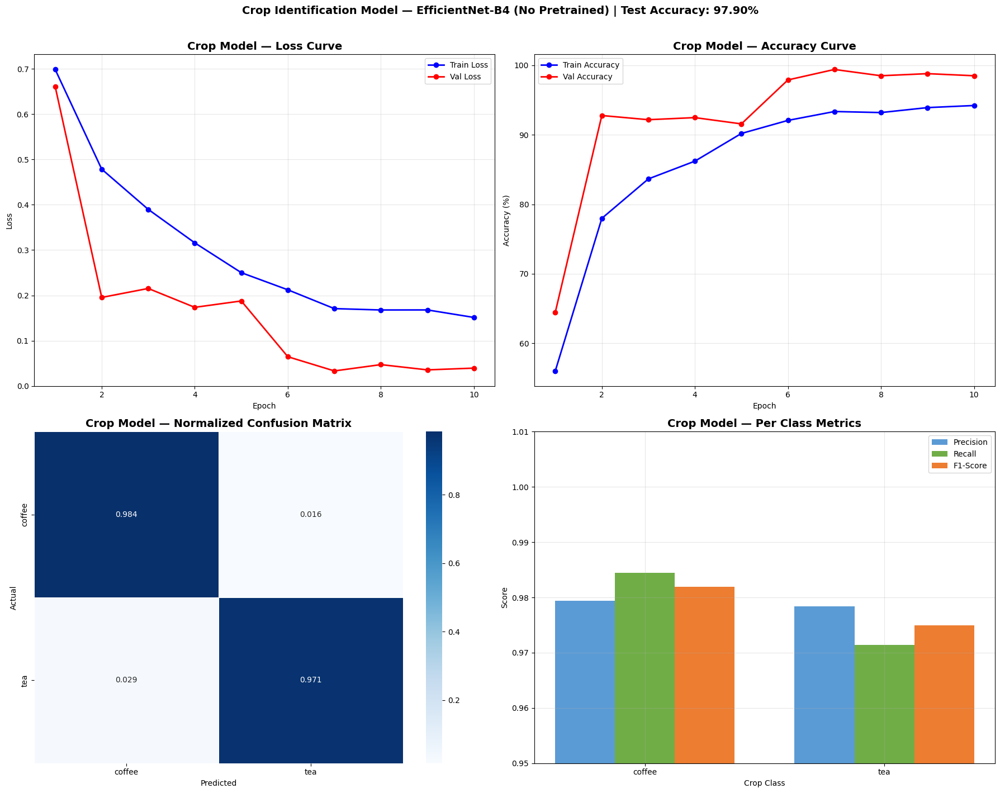

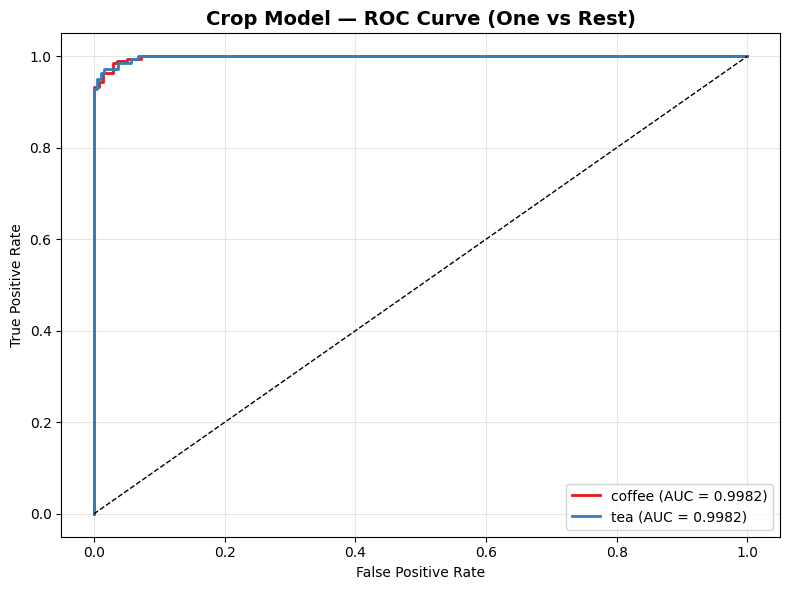

Saved: crop_model_results.png and crop_model_roc.png


In [31]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

fig, axes = plt.subplots(2, 2, figsize=(18, 14))

epochs_range = range(1, len(train_losses) + 1)
axes[0, 0].plot(epochs_range, train_losses, 'b-o', label='Train Loss', linewidth=2)
axes[0, 0].plot(epochs_range, val_losses,   'r-o', label='Val Loss',   linewidth=2)
axes[0, 0].set_title('Crop Model — Loss Curve', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(epochs_range, train_accs, 'b-o', label='Train Accuracy', linewidth=2)
axes[0, 1].plot(epochs_range, val_accs,   'r-o', label='Val Accuracy',   linewidth=2)
axes[0, 1].set_title('Crop Model — Accuracy Curve', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy (%)')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

cm = confusion_matrix(all_labels, all_preds)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt='.3f', cmap='Blues',
            xticklabels=CROP_CLASSES, yticklabels=CROP_CLASSES,
            ax=axes[1, 0], linewidths=0.5)
axes[1, 0].set_title('Crop Model — Normalized Confusion Matrix', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Predicted')
axes[1, 0].set_ylabel('Actual')

report = classification_report(all_labels, all_preds,
                                target_names=CROP_CLASSES, output_dict=True)
precisions = [report[c]['precision'] for c in CROP_CLASSES]
recalls    = [report[c]['recall']    for c in CROP_CLASSES]
f1s        = [report[c]['f1-score']  for c in CROP_CLASSES]
x     = np.arange(len(CROP_CLASSES))
width = 0.25
axes[1, 1].bar(x - width, precisions, width, label='Precision', color='#5b9bd5')
axes[1, 1].bar(x,          recalls,   width, label='Recall',    color='#70ad47')
axes[1, 1].bar(x + width,  f1s,       width, label='F1-Score',  color='#ed7d31')
axes[1, 1].set_title('Crop Model — Per Class Metrics', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Crop Class')
axes[1, 1].set_ylabel('Score')
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(CROP_CLASSES)
axes[1, 1].legend()
axes[1, 1].set_ylim(0.95, 1.01)
axes[1, 1].grid(True, alpha=0.3)

plt.suptitle('Crop Identification Model — EfficientNet-B4 (No Pretrained) | Test Accuracy: 97.90%',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('/kaggle/working/crop_model_results.png', dpi=150, bbox_inches='tight')
plt.show()

fig2, ax2 = plt.subplots(figsize=(8, 6))
coffee_probs = all_probs[:, 0]
fpr, tpr, _ = roc_curve((all_labels == 0).astype(int), coffee_probs)
roc_auc     = auc(fpr, tpr)
ax2.plot(fpr, tpr, color='#e41a1c', linewidth=2, label=f'coffee (AUC = {roc_auc:.4f})')

tea_probs = all_probs[:, 1]
fpr2, tpr2, _ = roc_curve((all_labels == 1).astype(int), tea_probs)
roc_auc2      = auc(fpr2, tpr2)
ax2.plot(fpr2, tpr2, color='#377eb8', linewidth=2, label=f'tea (AUC = {roc_auc2:.4f})')

ax2.plot([0, 1], [0, 1], 'k--', linewidth=1)
ax2.set_title('Crop Model — ROC Curve (One vs Rest)', fontsize=14, fontweight='bold')
ax2.set_xlabel('False Positive Rate')
ax2.set_ylabel('True Positive Rate')
ax2.legend(loc='lower right')
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('/kaggle/working/crop_model_roc.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: crop_model_results.png and crop_model_roc.png")

# Sample Predictions — Crop Model

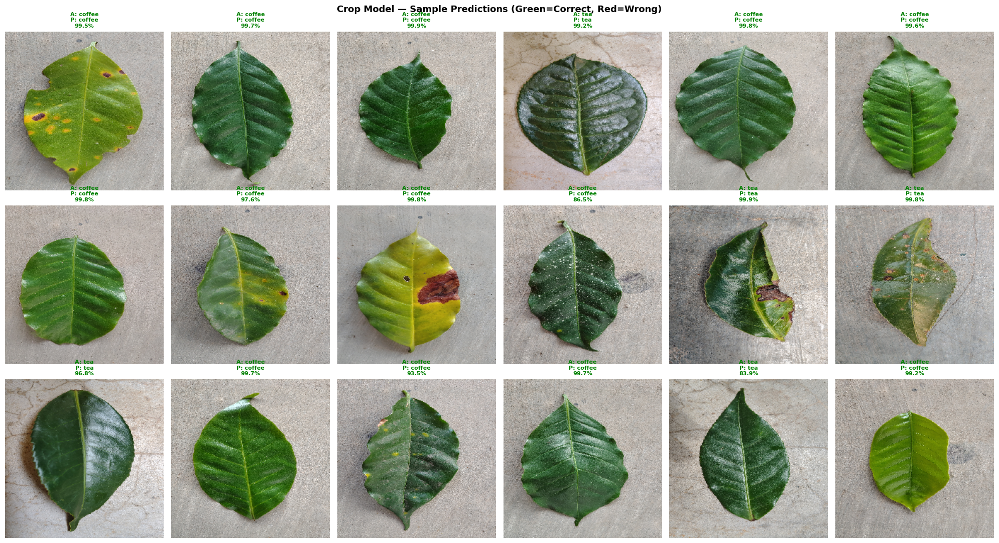

Saved: crop_model_predictions.png


In [32]:
crop_model.eval()
fig, axes = plt.subplots(3, 6, figsize=(20, 11))
axes = axes.flatten()

sample_indices = np.random.choice(len(test_df), 18, replace=False)

for i, idx in enumerate(sample_indices):
    row = test_df.iloc[idx]
    img_orig = cv2.imread(row['path'])
    img_orig = cv2.cvtColor(img_orig, cv2.COLOR_BGR2RGB)
    img_orig = cv2.resize(img_orig, (224, 224))

    from torchvision import transforms
    from PIL import Image
    val_tf = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    img_tensor = val_tf(Image.open(row['path']).convert('RGB')).unsqueeze(0).to(device)

    with torch.no_grad():
        output = crop_model(img_tensor)
        prob   = torch.softmax(output, dim=1)
        pred_idx    = output.argmax(dim=1).item()
        confidence  = prob[0][pred_idx].item() * 100

    actual    = row['crop']
    predicted = CROP_CLASSES[pred_idx]
    color     = 'green' if predicted == actual else 'red'

    axes[i].imshow(img_orig)
    axes[i].set_title(f"A: {actual}\nP: {predicted}\n{confidence:.1f}%",
                      fontsize=8, color=color, fontweight='bold')
    axes[i].axis('off')

plt.suptitle('Crop Model — Sample Predictions (Green=Correct, Red=Wrong)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/crop_model_predictions.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: crop_model_predictions.png")

# Build Health Model — Hybrid EfficientNet-B4 + ViT

In [33]:
from torchvision.models import ViT_B_16_Weights

class HealthModel(nn.Module):
    def __init__(self, num_classes=2):
        super(HealthModel, self).__init__()
        self.efficientnet = models.efficientnet_b4(
            weights=models.EfficientNet_B4_Weights.IMAGENET1K_V1
        )
        self.efficientnet.classifier = nn.Identity()
        self.eff_out_features = 1792

        self.vit = models.vit_b_16(weights=ViT_B_16_Weights.IMAGENET1K_V1)
        self.vit.heads = nn.Identity()
        self.vit_out_features = 768

        combined = self.eff_out_features + self.vit_out_features

        self.fusion = nn.Sequential(
            nn.Linear(combined, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        eff_features = self.efficientnet(x)
        vit_features = self.vit(x)
        combined     = torch.cat([eff_features, vit_features], dim=1)
        out          = self.fusion(combined)
        return out

health_model = HealthModel(num_classes=len(HEALTH_CLASSES)).to(device)

health_weight_tensor = torch.tensor(health_weight_list, dtype=torch.float32).to(device)
criterion_health     = nn.CrossEntropyLoss(weight=health_weight_tensor)
optimizer_health     = torch.optim.AdamW(health_model.parameters(), lr=5e-5, weight_decay=1e-4)
scheduler_health     = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_health, T_max=20, eta_min=1e-6
)

total_params     = sum(p.numel() for p in health_model.parameters())
trainable_params = sum(p.numel() for p in health_model.parameters() if p.requires_grad)
print(f"Device               : {device}")
print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")
print(f"Criterion            : CrossEntropyLoss with class weights")
print(f"Optimizer            : AdamW (lr=5e-5, weight_decay=1e-4)")
print(f"Scheduler            : CosineAnnealingLR (T_max=20)")
print(f"Num classes          : {len(HEALTH_CLASSES)} — {HEALTH_CLASSES}")

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 190MB/s]  


Device               : cuda
Total parameters     : 104,791,882
Trainable parameters : 104,791,882
Criterion            : CrossEntropyLoss with class weights
Optimizer            : AdamW (lr=5e-5, weight_decay=1e-4)
Scheduler            : CosineAnnealingLR (T_max=20)
Num classes          : 2 — ['healthy', 'unhealthy']


# Train Health Model

In [35]:
NUM_EPOCHS_HEALTH = 5
best_val_acc_h = 0.0
best_epoch_h = 0
train_losses_h, val_losses_h = [], []
train_accs_h, val_accs_h = [], []
early_stop_patience_h = 3
no_improve_count_h = 0

print(f"Starting Health Model Training — {NUM_EPOCHS_HEALTH} epochs")
print(f"{'Epoch':<8}{'Train Loss':<14}{'Train Acc':<14}{'Val Loss':<14}{'Val Acc':<14}{'LR':<12}{'Time'}")
print("-" * 90)

for epoch in range(1, NUM_EPOCHS_HEALTH + 1):
    start = time.time()

    health_model.train()
    train_loss_h, train_correct_h, train_total_h = 0.0, 0, 0

    train_bar = tqdm(health_train_loader, desc=f"Epoch {epoch}/{NUM_EPOCHS_HEALTH} [Train]", leave=False)
    for imgs, labels in train_bar:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer_health.zero_grad()
        outputs = health_model(imgs)
        loss = criterion_health(outputs, labels)
        loss.backward()
        optimizer_health.step()
        train_loss_h += loss.item() * imgs.size(0)
        preds = outputs.argmax(dim=1)
        train_correct_h += (preds == labels).sum().item()
        train_total_h += imgs.size(0)
        train_bar.set_postfix({
            'loss': f"{train_loss_h/train_total_h:.4f}",
            'acc':  f"{train_correct_h/train_total_h*100:.2f}%"
        })

    health_model.eval()
    val_loss_h, val_correct_h, val_total_h = 0.0, 0, 0

    val_bar = tqdm(health_val_loader, desc=f"Epoch {epoch}/{NUM_EPOCHS_HEALTH} [Val]  ", leave=False)
    with torch.no_grad():
        for imgs, labels in val_bar:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = health_model(imgs)
            loss = criterion_health(outputs, labels)
            val_loss_h += loss.item() * imgs.size(0)
            preds = outputs.argmax(dim=1)
            val_correct_h += (preds == labels).sum().item()
            val_total_h += imgs.size(0)
            val_bar.set_postfix({
                'loss': f"{val_loss_h/val_total_h:.4f}",
                'acc':  f"{val_correct_h/val_total_h*100:.2f}%"
            })

    avg_train_loss_h = train_loss_h / train_total_h
    avg_val_loss_h   = val_loss_h   / val_total_h
    avg_train_acc_h  = train_correct_h / train_total_h * 100
    avg_val_acc_h    = val_correct_h   / val_total_h   * 100
    current_lr_h     = optimizer_health.param_groups[0]['lr']
    elapsed          = time.time() - start

    train_losses_h.append(avg_train_loss_h)
    val_losses_h.append(avg_val_loss_h)
    train_accs_h.append(avg_train_acc_h)
    val_accs_h.append(avg_val_acc_h)

    scheduler_health.step()

    if avg_val_acc_h > best_val_acc_h:
        best_val_acc_h = avg_val_acc_h
        best_epoch_h   = epoch
        torch.save(health_model.state_dict(), '/kaggle/working/health_model_best.pth')
        flag = 'SAVED'
        no_improve_count_h = 0
    else:
        flag = ''
        no_improve_count_h += 1

    print(f"{epoch:<8}{avg_train_loss_h:<14.4f}{avg_train_acc_h:<14.2f}{avg_val_loss_h:<14.4f}{avg_val_acc_h:<14.2f}{current_lr_h:<12.6f}{elapsed:.1f}s  {flag}")

    if no_improve_count_h >= early_stop_patience_h:
        print(f"\nEarly stopping at epoch {epoch} — no improvement for {early_stop_patience_h} epochs")
        break

print(f"\nBest Val Accuracy : {best_val_acc_h:.2f}% at epoch {best_epoch_h}")
print(f"Model saved to    : /kaggle/working/health_model_best.pth")

Starting Health Model Training — 5 epochs
Epoch   Train Loss    Train Acc     Val Loss      Val Acc       LR          Time
------------------------------------------------------------------------------------------


1       0.1914        94.55         0.2777        89.46         0.000050    288.0s  SAVED


2       0.1493        95.38         0.1334        95.18         0.000050    282.9s  SAVED


3       0.1154        95.98         0.1236        95.48         0.000049    269.7s  SAVED


4       0.1140        95.75         0.1239        95.48         0.000047    271.0s  


5       0.0984        95.94         0.1157        95.78         0.000045    272.2s  SAVED

Best Val Accuracy : 95.78% at epoch 5
Model saved to    : /kaggle/working/health_model_best.pth


# Evaluate Health Model on Test Set

In [36]:
health_model.load_state_dict(torch.load('/kaggle/working/health_model_best.pth'))
health_model.eval()

all_preds_h, all_labels_h, all_probs_h = [], [], []

with torch.no_grad():
    for imgs, labels in health_test_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = health_model(imgs)
        probs   = torch.softmax(outputs, dim=1)
        preds   = outputs.argmax(dim=1)
        all_preds_h.extend(preds.cpu().numpy())
        all_labels_h.extend(labels.cpu().numpy())
        all_probs_h.extend(probs.cpu().numpy())

all_preds_h  = np.array(all_preds_h)
all_labels_h = np.array(all_labels_h)
all_probs_h  = np.array(all_probs_h)

test_acc_h = (all_preds_h == all_labels_h).mean() * 100
print(f"Health Model Test Accuracy: {test_acc_h:.2f}%")
print(f"\nClassification Report:")
print(classification_report(all_labels_h, all_preds_h,
                             target_names=HEALTH_CLASSES, digits=4))

Health Model Test Accuracy: 95.50%

Classification Report:
              precision    recall  f1-score   support

     healthy     0.9627    0.9451    0.9538       164
   unhealthy     0.9477    0.9645    0.9560       169

    accuracy                         0.9550       333
   macro avg     0.9552    0.9548    0.9549       333
weighted avg     0.9551    0.9550    0.9549       333



# Graphs — Health Model

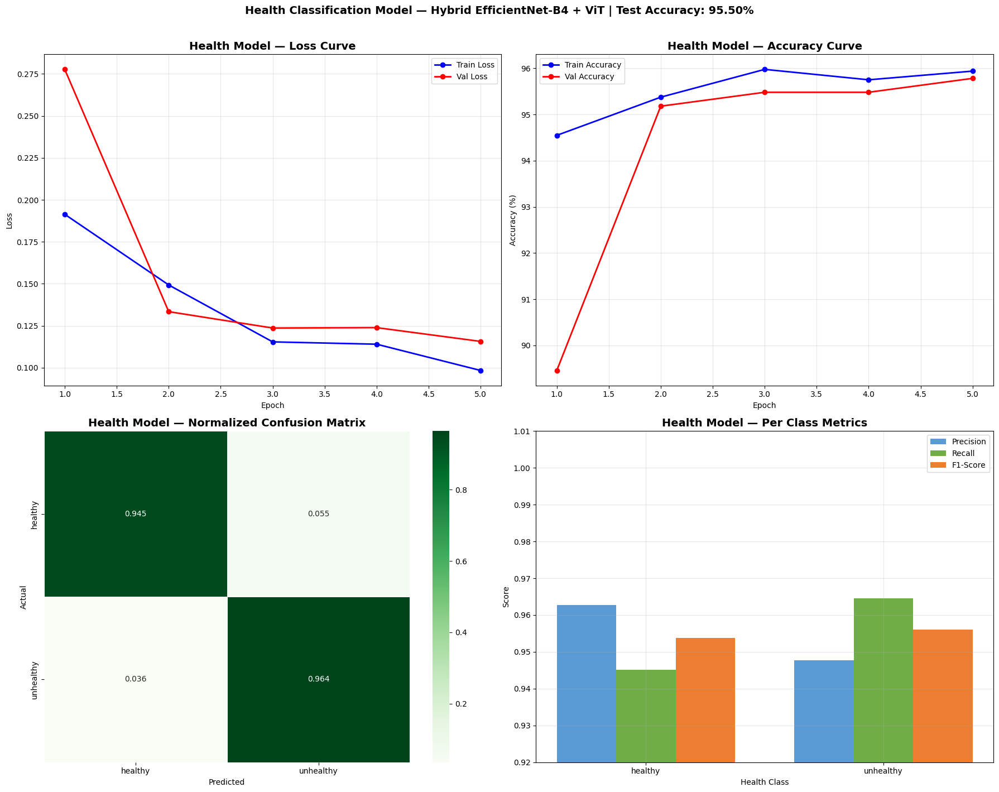

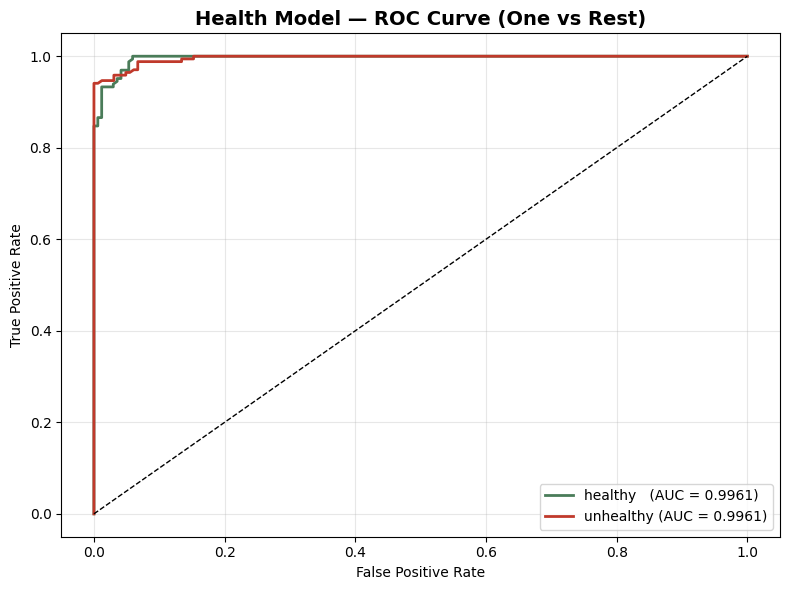

Saved: health_model_results.png and health_model_roc.png


In [37]:
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

epochs_range_h = range(1, len(train_losses_h) + 1)
axes[0, 0].plot(epochs_range_h, train_losses_h, 'b-o', label='Train Loss', linewidth=2)
axes[0, 0].plot(epochs_range_h, val_losses_h,   'r-o', label='Val Loss',   linewidth=2)
axes[0, 0].set_title('Health Model — Loss Curve', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(epochs_range_h, train_accs_h, 'b-o', label='Train Accuracy', linewidth=2)
axes[0, 1].plot(epochs_range_h, val_accs_h,   'r-o', label='Val Accuracy',   linewidth=2)
axes[0, 1].set_title('Health Model — Accuracy Curve', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy (%)')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

cm_h = confusion_matrix(all_labels_h, all_preds_h)
cm_norm_h = cm_h.astype('float') / cm_h.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm_h, annot=True, fmt='.3f', cmap='Greens',
            xticklabels=HEALTH_CLASSES, yticklabels=HEALTH_CLASSES,
            ax=axes[1, 0], linewidths=0.5)
axes[1, 0].set_title('Health Model — Normalized Confusion Matrix', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Predicted')
axes[1, 0].set_ylabel('Actual')

report_h   = classification_report(all_labels_h, all_preds_h,
                                    target_names=HEALTH_CLASSES, output_dict=True)
precisions_h = [report_h[c]['precision'] for c in HEALTH_CLASSES]
recalls_h    = [report_h[c]['recall']    for c in HEALTH_CLASSES]
f1s_h        = [report_h[c]['f1-score']  for c in HEALTH_CLASSES]
x_h     = np.arange(len(HEALTH_CLASSES))
width   = 0.25
axes[1, 1].bar(x_h - width, precisions_h, width, label='Precision', color='#5b9bd5')
axes[1, 1].bar(x_h,          recalls_h,   width, label='Recall',    color='#70ad47')
axes[1, 1].bar(x_h + width,  f1s_h,       width, label='F1-Score',  color='#ed7d31')
axes[1, 1].set_title('Health Model — Per Class Metrics', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Health Class')
axes[1, 1].set_ylabel('Score')
axes[1, 1].set_xticks(x_h)
axes[1, 1].set_xticklabels(HEALTH_CLASSES)
axes[1, 1].legend()
axes[1, 1].set_ylim(0.92, 1.01)
axes[1, 1].grid(True, alpha=0.3)

plt.suptitle('Health Classification Model — Hybrid EfficientNet-B4 + ViT | Test Accuracy: 95.50%',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('/kaggle/working/health_model_results.png', dpi=150, bbox_inches='tight')
plt.show()

fig2, ax2 = plt.subplots(figsize=(8, 6))
healthy_probs   = all_probs_h[:, 0]
unhealthy_probs = all_probs_h[:, 1]

fpr_h,  tpr_h,  _ = roc_curve((all_labels_h == 0).astype(int), healthy_probs)
fpr_u,  tpr_u,  _ = roc_curve((all_labels_h == 1).astype(int), unhealthy_probs)
auc_h = auc(fpr_h, tpr_h)
auc_u = auc(fpr_u, tpr_u)

ax2.plot(fpr_h, tpr_h, color='#4A7C59', linewidth=2, label=f'healthy   (AUC = {auc_h:.4f})')
ax2.plot(fpr_u, tpr_u, color='#C0392B', linewidth=2, label=f'unhealthy (AUC = {auc_u:.4f})')
ax2.plot([0, 1], [0, 1], 'k--', linewidth=1)
ax2.set_title('Health Model — ROC Curve (One vs Rest)', fontsize=14, fontweight='bold')
ax2.set_xlabel('False Positive Rate')
ax2.set_ylabel('True Positive Rate')
ax2.legend(loc='lower right')
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('/kaggle/working/health_model_roc.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: health_model_results.png and health_model_roc.png")

# Sample Predictions — Health Model

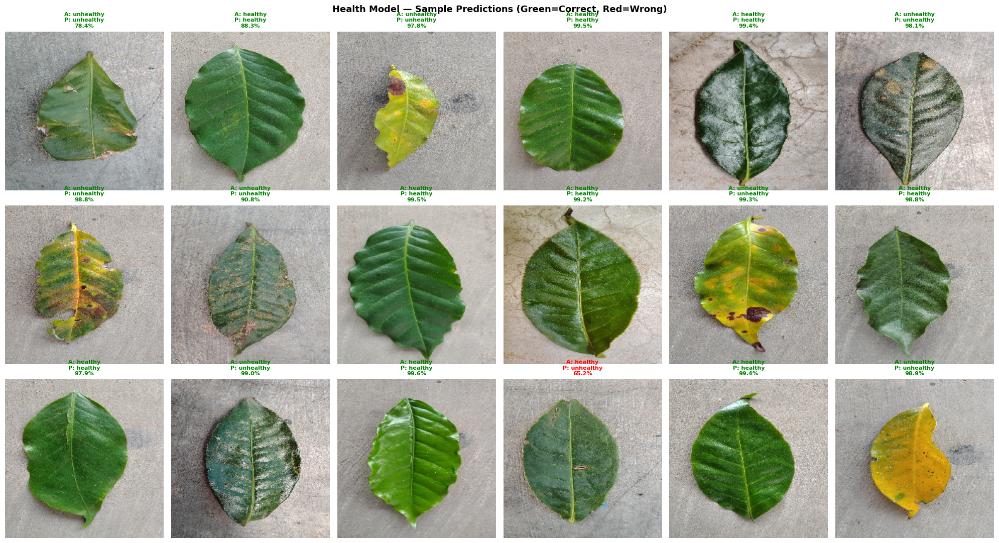

Saved: health_model_predictions.png


In [38]:
health_model.eval()
fig, axes = plt.subplots(3, 6, figsize=(20, 11))
axes = axes.flatten()

from PIL import Image as PILImage
val_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

sample_indices = np.random.choice(len(test_df), 18, replace=False)

for i, idx in enumerate(sample_indices):
    row = test_df.iloc[idx]
    img_orig = cv2.imread(row['path'])
    img_orig = cv2.cvtColor(img_orig, cv2.COLOR_BGR2RGB)
    img_orig = cv2.resize(img_orig, (224, 224))

    img_tensor = val_tf(PILImage.open(row['path']).convert('RGB')).unsqueeze(0).to(device)

    with torch.no_grad():
        output     = health_model(img_tensor)
        prob       = torch.softmax(output, dim=1)
        pred_idx   = output.argmax(dim=1).item()
        confidence = prob[0][pred_idx].item() * 100

    actual    = row['health']
    predicted = HEALTH_CLASSES[pred_idx]
    color     = 'green' if predicted == actual else 'red'

    axes[i].imshow(img_orig)
    axes[i].set_title(f"A: {actual}\nP: {predicted}\n{confidence:.1f}%",
                      fontsize=8, color=color, fontweight='bold')
    axes[i].axis('off')

plt.suptitle('Health Model — Sample Predictions (Green=Correct, Red=Wrong)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/health_model_predictions.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: health_model_predictions.png")

# Color Filter + Severity — Test on Coffee and Tea Samples

COLOR FILTER + SEVERITY — RECALIBRATED:
[Coffee Unhealthy] Colors: ['black'] | Severity: Mild (3.5%)
[Coffee Unhealthy] Colors: ['brown', 'yellow'] | Severity: Severe (85.2%)
[Tea Unhealthy] Colors: ['brown', 'black', 'gray'] | Severity: Severe (42.5%)
[Tea Unhealthy] Colors: ['black', 'gray'] | Severity: Severe (44.8%)


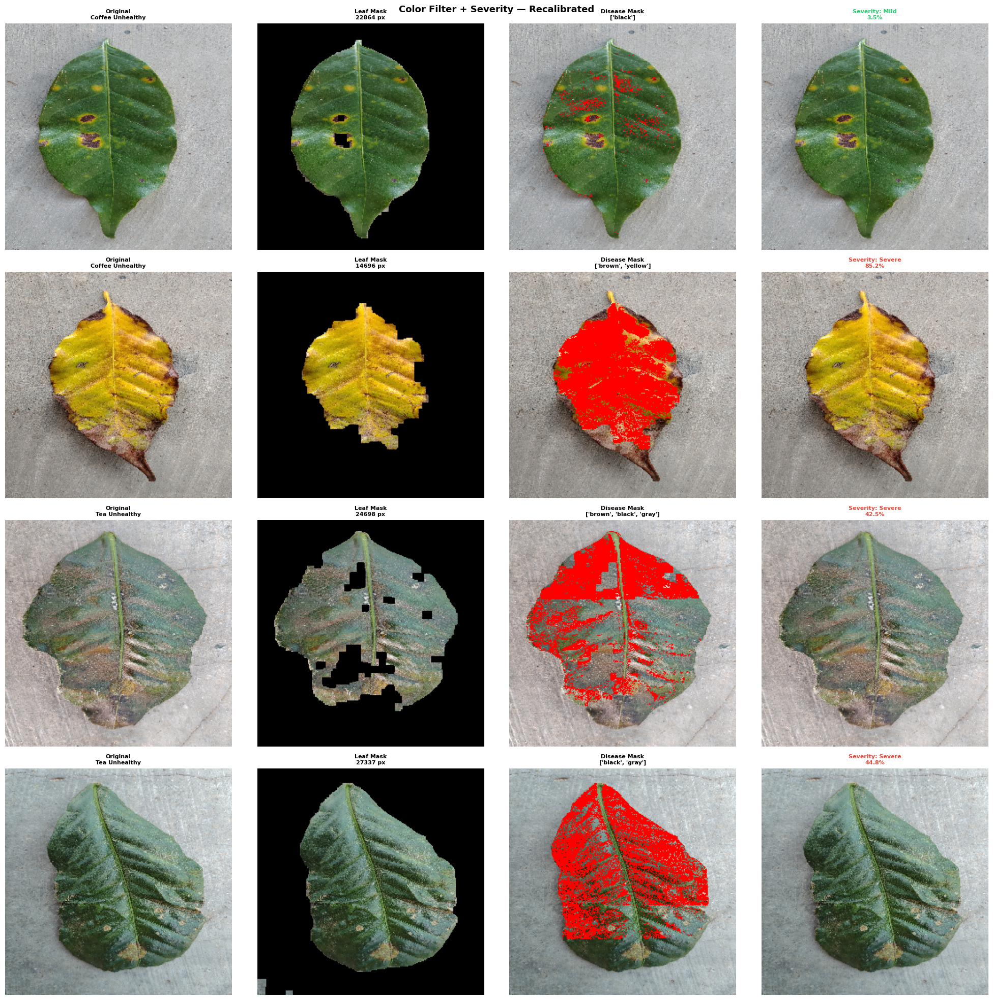


Saved: color_filter_recalibrated.png


In [40]:
def get_leaf_mask(img_bgr):
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    lower_green = np.array([20, 30, 30])
    upper_green = np.array([90, 255, 255])
    leaf_mask = cv2.inRange(hsv, lower_green, upper_green)
    kernel = np.ones((7, 7), np.uint8)
    leaf_mask = cv2.morphologyEx(leaf_mask, cv2.MORPH_CLOSE, kernel)
    leaf_mask = cv2.morphologyEx(leaf_mask, cv2.MORPH_OPEN, kernel)
    leaf_pixel_count = np.sum(leaf_mask > 0)
    total_pixels = img_bgr.shape[0] * img_bgr.shape[1]
    if leaf_pixel_count < total_pixels * 0.1:
        gray_img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
        _, leaf_mask = cv2.threshold(gray_img, 30, 255, cv2.THRESH_BINARY)
    return leaf_mask

COLOR_RANGES = {
    'brown': [([0,  40, 30],  [18, 255, 170]),
              ([18, 40, 60],  [25, 180, 160])],
    'black': [([0,  0,  0],   [180, 120, 90])],
    'yellow':[([20, 80, 150], [35, 255, 255])],
    'white': [([0,  0,  185], [180, 50,  255])],
    'gray':  [([0,  0,  55],  [180, 55,  195])],
}

COLOR_THRESHOLDS = {
    'brown':  0.02,
    'black':  0.01,
    'yellow': 0.10,
    'white':  0.04,
    'gray':   0.04,
}

COLOR_CAP = {'gray': 0.25, 'black': 0.20}

unhealthy_samples = [
    (coffee_path / 'UNHEALTHY', 'Coffee Unhealthy'),
    (tea_path    / 'UNHEALTHY', 'Tea Unhealthy'),
]

fig, axes = plt.subplots(4, 4, figsize=(20, 20))

print("COLOR FILTER + SEVERITY — RECALIBRATED:")
print("=" * 60)

import random
random.seed(42)
row_idx = 0

for cls_path, label in unhealthy_samples:
    images  = list(cls_path.glob('*.jpg'))
    sampled = random.sample(images, 2)

    for img_path in sampled:
        img_bgr   = cv2.imread(str(img_path))
        img_bgr   = cv2.resize(img_bgr, (256, 256))
        img_rgb   = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        leaf_mask = get_leaf_mask(img_bgr)
        detected_colors, disease_mask, severity_pct, severity_label = \
            detect_colors_and_severity(img_bgr, leaf_mask)

        leaf_overlay    = img_rgb.copy()
        leaf_overlay[leaf_mask == 0] = [0, 0, 0]
        disease_overlay = img_rgb.copy()
        disease_overlay[disease_mask > 0] = [255, 0, 0]
        sev_color = '#2ecc71' if severity_label == 'Mild' else \
                    '#f39c12' if severity_label == 'Moderate' else '#e74c3c'

        axes[row_idx][0].imshow(img_rgb)
        axes[row_idx][0].set_title(f'Original\n{label}', fontweight='bold', fontsize=8)
        axes[row_idx][0].axis('off')

        axes[row_idx][1].imshow(leaf_overlay)
        axes[row_idx][1].set_title(f'Leaf Mask\n{np.sum(leaf_mask>0)} px',
                                    fontweight='bold', fontsize=8)
        axes[row_idx][1].axis('off')

        axes[row_idx][2].imshow(disease_overlay)
        axes[row_idx][2].set_title(f'Disease Mask\n{detected_colors}',
                                    fontweight='bold', fontsize=8)
        axes[row_idx][2].axis('off')

        axes[row_idx][3].imshow(img_rgb)
        axes[row_idx][3].set_title(f'Severity: {severity_label}\n{severity_pct:.1f}%',
                                    fontweight='bold', fontsize=8, color=sev_color)
        axes[row_idx][3].axis('off')

        print(f"[{label}] Colors: {detected_colors} | "
              f"Severity: {severity_label} ({severity_pct:.1f}%)")
        row_idx += 1

plt.suptitle('Color Filter + Severity — Recalibrated',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/color_filter_recalibrated.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nSaved: color_filter_recalibrated.png")

# Full Pipeline Test — All Together

#   Actual Crop   Pred Crop     Actual Health   Pred Health     Conf%   Colors                        Severity
--------------------------------------------------------------------------------------------------------------
1   coffee        coffee✓       healthy         healthy✓        99.56   ['gray']                      Mild (6.17%)
2   coffee        coffee✓       healthy         healthy✓        99.52   ['black', 'gray']             Mild (14.27%)
3   coffee        coffee✓       unhealthy       unhealthy✓      99.19   ['brown', 'yellow']           Severe (79.78%)
4   coffee        coffee✓       unhealthy       unhealthy✓      80.71   ['black', 'gray']             Mild (14.02%)
5   tea           tea✓          healthy         healthy✓        99.16   ['black', 'white', 'gray']    Severe (48.5%)
6   tea           tea✓          healthy         healthy✓        99.48   ['black', 'gray']             Moderate (32.24%)
7   tea           tea✓          unhealthy       unhealthy✓      81.87   ['br

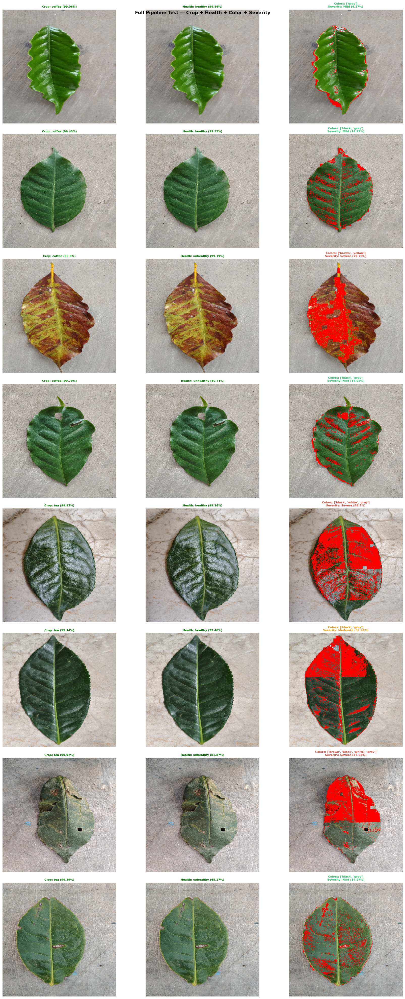


Saved: full_pipeline_test.png


In [41]:
from PIL import Image as PILImage
from torchvision import transforms as T

val_tf = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def predict_full_pipeline(img_path):
    img_bgr     = cv2.imread(img_path)
    img_bgr_r   = cv2.resize(img_bgr, (256, 256))
    img_tensor  = val_tf(PILImage.open(img_path).convert('RGB')).unsqueeze(0).to(device)

    crop_model.eval()
    health_model.eval()

    with torch.no_grad():
        crop_out   = crop_model(img_tensor)
        crop_prob  = torch.softmax(crop_out, dim=1)
        crop_idx   = crop_out.argmax(dim=1).item()
        crop_conf  = round(crop_prob[0][crop_idx].item() * 100, 2)
        crop_pred  = CROP_CLASSES[crop_idx]

        health_out  = health_model(img_tensor)
        health_prob = torch.softmax(health_out, dim=1)
        health_idx  = health_out.argmax(dim=1).item()
        health_conf = round(health_prob[0][health_idx].item() * 100, 2)
        health_pred = HEALTH_CLASSES[health_idx]

    leaf_mask = get_leaf_mask(img_bgr_r)
    detected_colors, disease_mask, severity_pct, severity_label = \
        detect_colors_and_severity(img_bgr_r, leaf_mask)

    return {
        'crop':           crop_pred,
        'crop_conf':      crop_conf,
        'health':         health_pred,
        'health_conf':    health_conf,
        'colors':         detected_colors,
        'severity':       severity_label,
        'severity_pct':   round(severity_pct, 2),
        'disease_mask':   disease_mask,
        'img_rgb':        cv2.cvtColor(img_bgr_r, cv2.COLOR_BGR2RGB),
    }

import random
random.seed(77)

test_samples = []
for crop_label, crop_dir in [('coffee', coffee_path), ('tea', tea_path)]:
    for health_label in ['HEALTHY', 'UNHEALTHY']:
        cls_dir = crop_dir / health_label
        imgs    = list(cls_dir.glob('*.jpg'))
        picked  = random.sample(imgs, 2)
        for p in picked:
            test_samples.append((str(p), crop_label, health_label.lower()))

print(f"{'#':<4}{'Actual Crop':<14}{'Pred Crop':<14}{'Actual Health':<16}{'Pred Health':<16}{'Conf%':<8}{'Colors':<30}{'Severity'}")
print("-" * 110)

fig, axes = plt.subplots(len(test_samples), 3, figsize=(18, 5 * len(test_samples)))

for i, (img_path, actual_crop, actual_health) in enumerate(test_samples):
    result = predict_full_pipeline(img_path)

    crop_ok   = '✓' if result['crop']   == actual_crop   else '✗'
    health_ok = '✓' if result['health'] == actual_health else '✗'

    print(f"{i+1:<4}{actual_crop:<14}{result['crop']+crop_ok:<14}"
          f"{actual_health:<16}{result['health']+health_ok:<16}"
          f"{result['health_conf']:<8}"
          f"{str(result['colors']):<30}{result['severity']} ({result['severity_pct']}%)")

    disease_overlay = result['img_rgb'].copy()
    disease_overlay[result['disease_mask'] > 0] = [255, 0, 0]

    axes[i][0].imshow(result['img_rgb'])
    crop_color   = 'green' if result['crop']   == actual_crop   else 'red'
    health_color = 'green' if result['health'] == actual_health else 'red'
    axes[i][0].set_title(f"Crop: {result['crop']} ({result['crop_conf']}%)",
                          fontsize=8, fontweight='bold', color=crop_color)
    axes[i][0].axis('off')

    axes[i][1].imshow(result['img_rgb'])
    axes[i][1].set_title(f"Health: {result['health']} ({result['health_conf']}%)",
                          fontsize=8, fontweight='bold', color=health_color)
    axes[i][1].axis('off')

    sev_color = '#2ecc71' if result['severity']=='Mild' else \
                '#f39c12' if result['severity']=='Moderate' else '#e74c3c'
    axes[i][2].imshow(disease_overlay)
    axes[i][2].set_title(f"Colors: {result['colors']}\nSeverity: {result['severity']} ({result['severity_pct']}%)",
                          fontsize=8, fontweight='bold', color=sev_color)
    axes[i][2].axis('off')

plt.suptitle('Full Pipeline Test — Crop + Health + Color + Severity',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/full_pipeline_test.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nSaved: full_pipeline_test.png")

# Build Knowledge Base In-Memory and Test Matching

In [43]:
import sqlite3
import os

DB_PATH = '/kaggle/working/tea_coffee.db'

if os.path.exists(DB_PATH):
    os.remove(DB_PATH)

conn = sqlite3.connect(DB_PATH)
conn.row_factory = sqlite3.Row
cursor = conn.cursor()

cursor.execute('''
    CREATE TABLE IF NOT EXISTS knowledge_base (
        id          INTEGER PRIMARY KEY AUTOINCREMENT,
        crop        TEXT NOT NULL,
        disease     TEXT NOT NULL,
        health      TEXT NOT NULL,
        colors      TEXT NOT NULL,
        description TEXT,
        treatment   TEXT
    )
''')

diseases = [
    ('coffee', 'Coffee Leaf Rust',          'unhealthy', 'brown,yellow',
     'Fungal disease causing orange-yellow powdery pustules on the underside of leaves.',
     'Apply copper-based fungicides. Remove and destroy infected leaves. Improve air circulation.'),

    ('coffee', 'Coffee Phoma Blight',       'unhealthy', 'brown,black',
     'Fungal disease causing dark brown to black necrotic lesions on leaves and stems.',
     'Apply mancozeb or carbendazim fungicides. Prune infected branches. Avoid waterlogging.'),

    ('coffee', 'Coffee Chlorosis',          'unhealthy', 'yellow,white',
     'Nutrient deficiency or viral condition causing yellowing and whitening of leaf tissue.',
     'Apply balanced fertilizers with iron and magnesium. Test soil pH. Remove severely affected plants.'),

    ('coffee', 'Coffee Cercospora Leaf Spot','unhealthy', 'brown,gray',
     'Fungal disease causing circular brown spots with gray centers on coffee leaves.',
     'Apply copper fungicides. Remove infected leaves. Maintain proper plant spacing.'),

    ('coffee', 'Coffee Sooty Mold',         'unhealthy', 'black,gray',
     'Fungal growth on honeydew secreted by insects causing black coating on leaf surface.',
     'Control insect populations with insecticides. Wash leaves with soapy water. Improve ventilation.'),

    ('coffee', 'Coffee Bacterial Blight',   'unhealthy', 'brown,black,gray',
     'Bacterial infection causing water-soaked lesions that turn brown and black on leaves.',
     'Apply copper bactericides. Avoid overhead irrigation. Remove and destroy infected plant material.'),

    ('coffee', 'Healthy Coffee Leaf',       'healthy',   '',
     'Leaf shows no signs of disease or stress. Plant is in good health.',
     'Continue current care practices. Maintain regular fertilization and irrigation schedule.'),

    ('tea', 'Tea Blister Blight',           'unhealthy', 'white,gray',
     'Fungal disease causing blister-like white spots on young tea leaves.',
     'Apply copper oxychloride fungicides. Avoid working in plantations during wet weather.'),

    ('tea', 'Tea Red Spot',                 'unhealthy', 'brown,black',
     'Fungal disease causing small reddish-brown circular spots on mature tea leaves.',
     'Apply mancozeb fungicides. Remove infected leaves. Improve drainage in the plantation.'),

    ('tea', 'Tea Algal Leaf Spot',          'unhealthy', 'gray,white',
     'Algal infection causing raised gray-green to white crusty spots on tea leaf surface.',
     'Apply copper fungicides. Improve air circulation. Reduce shade and humidity around plants.'),

    ('tea', 'Tea Gray Blight',              'unhealthy', 'gray,brown',
     'Fungal disease causing gray-brown necrotic patches that spread across tea leaves.',
     'Apply carbendazim or mancozeb fungicides. Remove infected leaves. Maintain plantation hygiene.'),

    ('tea', 'Tea Brown Blight',             'unhealthy', 'brown,black',
     'Fungal disease causing brown water-soaked lesions that turn dark and spread rapidly.',
     'Apply copper-based fungicides immediately. Remove severely infected branches. Avoid wet conditions.'),

    ('tea', 'Tea White Spot',               'unhealthy', 'white,black',
     'Fungal disease causing circular white spots with dark borders on tea leaves.',
     'Apply fungicides containing hexaconazole. Remove infected plant debris. Improve drainage.'),

    ('tea', 'Tea Anthracnose',              'unhealthy', 'brown,black,gray',
     'Fungal disease causing dark sunken lesions on tea leaves, often with yellow halos.',
     'Apply mancozeb or copper fungicides. Prune infected parts. Avoid waterlogging conditions.'),

    ('tea', 'Tea Chlorosis',                'unhealthy', 'yellow,white',
     'Nutrient deficiency causing yellowing of tea leaves due to lack of iron or magnesium.',
     'Apply chelated iron or magnesium sulfate. Test and adjust soil pH. Improve drainage.'),

    ('tea', 'Healthy Tea Leaf',             'healthy',   '',
     'Leaf shows no signs of disease or stress. Plant is in good health.',
     'Continue current care practices. Monitor regularly for early signs of disease.'),
]

cursor.executemany('''
    INSERT INTO knowledge_base (crop, disease, health, colors, description, treatment)
    VALUES (?, ?, ?, ?, ?, ?)
''', diseases)

conn.commit()

cursor.execute('SELECT COUNT(*) FROM knowledge_base')
print(f"Knowledge base created: {cursor.fetchone()[0]} diseases loaded")
cursor.execute('SELECT crop, disease, health, colors FROM knowledge_base')
rows = cursor.fetchall()
print(f"\n{'Crop':<10}{'Disease':<30}{'Health':<12}{'Colors'}")
print("-" * 70)
for row in rows:
    print(f"{row['crop']:<10}{row['disease']:<30}{row['health']:<12}{row['colors']}")
conn.close()

Knowledge base created: 16 diseases loaded

Crop      Disease                       Health      Colors
----------------------------------------------------------------------
coffee    Coffee Leaf Rust              unhealthy   brown,yellow
coffee    Coffee Phoma Blight           unhealthy   brown,black
coffee    Coffee Chlorosis              unhealthy   yellow,white
coffee    Coffee Cercospora Leaf Spot   unhealthy   brown,gray
coffee    Coffee Sooty Mold             unhealthy   black,gray
coffee    Coffee Bacterial Blight       unhealthy   brown,black,gray
coffee    Healthy Coffee Leaf           healthy     
tea       Tea Blister Blight            unhealthy   white,gray
tea       Tea Red Spot                  unhealthy   brown,black
tea       Tea Algal Leaf Spot           unhealthy   gray,white
tea       Tea Gray Blight               unhealthy   gray,brown
tea       Tea Brown Blight              unhealthy   brown,black
tea       Tea White Spot                unhealthy   white,black
tea

# KB Matching Function + Full Pipeline Test

In [44]:
def match_disease(predicted_crop, predicted_health, detected_colors):
    conn = sqlite3.connect(DB_PATH)
    conn.row_factory = sqlite3.Row
    cursor = conn.cursor()
    cursor.execute('SELECT * FROM knowledge_base')
    rows = cursor.fetchall()
    conn.close()

    KB_WEIGHTS = {'crop': 0.5, 'health': 0.3, 'color': 0.2}
    KB_MIN_SCORE = 0.4

    best_score = 0.0
    best_match = None

    for row in rows:
        score = 0.0

        if predicted_crop.lower() == row['crop'].lower():
            score += KB_WEIGHTS['crop']

        if predicted_health.lower() == row['health'].lower():
            score += KB_WEIGHTS['health']

        row_colors = [c.strip().lower() for c in row['colors'].split(',') if c.strip()]
        if detected_colors and row_colors:
            overlap    = len(set(detected_colors) & set(row_colors))
            color_score = overlap / len(row_colors)
            score += KB_WEIGHTS['color'] * color_score
        elif not detected_colors and not row_colors:
            score += KB_WEIGHTS['color']

        if score > best_score:
            best_score = score
            best_match = row

    if best_score < KB_MIN_SCORE or best_match is None:
        return {
            'disease':     'Condition Not Identified',
            'description': 'No matching condition found in knowledge base.',
            'treatment':   'Please consult an agricultural expert.',
            'match_score': round(best_score, 4)
        }

    return {
        'disease':     best_match['disease'],
        'description': best_match['description'],
        'treatment':   best_match['treatment'],
        'match_score': round(best_score, 4)
    }

def predict_full_pipeline_with_kb(img_path):
    img_bgr    = cv2.imread(img_path)
    img_bgr_r  = cv2.resize(img_bgr, (256, 256))
    img_tensor = val_tf(PILImage.open(img_path).convert('RGB')).unsqueeze(0).to(device)

    crop_model.eval()
    health_model.eval()

    with torch.no_grad():
        crop_out  = crop_model(img_tensor)
        crop_prob = torch.softmax(crop_out, dim=1)
        crop_idx  = crop_out.argmax(dim=1).item()
        crop_conf = round(crop_prob[0][crop_idx].item() * 100, 2)
        crop_pred = CROP_CLASSES[crop_idx]

        if crop_conf < 60.0:
            crop_pred = 'crop_not_supported'

        health_out  = health_model(img_tensor)
        health_prob = torch.softmax(health_out, dim=1)
        health_idx  = health_out.argmax(dim=1).item()
        health_conf = round(health_prob[0][health_idx].item() * 100, 2)
        health_pred = HEALTH_CLASSES[health_idx]

    leaf_mask = get_leaf_mask(img_bgr_r)
    detected_colors, disease_mask, severity_pct, severity_label = \
        detect_colors_and_severity(img_bgr_r, leaf_mask)

    kb_result = match_disease(crop_pred, health_pred, detected_colors)

    return {
        'crop':          crop_pred,
        'crop_conf':     crop_conf,
        'health':        health_pred,
        'health_conf':   health_conf,
        'colors':        detected_colors,
        'severity':      severity_label,
        'severity_pct':  round(severity_pct, 2),
        'disease':       kb_result['disease'],
        'description':   kb_result['description'],
        'treatment':     kb_result['treatment'],
        'match_score':   kb_result['match_score'],
    }

random.seed(77)
test_samples_kb = []
for crop_label, crop_dir in [('coffee', coffee_path), ('tea', tea_path)]:
    for health_label in ['HEALTHY', 'UNHEALTHY']:
        cls_dir = crop_dir / health_label
        imgs    = list(cls_dir.glob('*.jpg'))
        picked  = random.sample(imgs, 2)
        for p in picked:
            test_samples_kb.append((str(p), crop_label, health_label.lower()))

print(f"{'#':<3} {'Crop':<8} {'Health':<12} {'Disease':<30} {'Colors':<30} {'Severity':<12} {'Score'}")
print("-" * 105)

for i, (img_path, actual_crop, actual_health) in enumerate(test_samples_kb):
    r = predict_full_pipeline_with_kb(img_path)
    print(f"{i+1:<3} {r['crop']:<8} {r['health']:<12} {r['disease']:<30} "
          f"{str(r['colors']):<30} {r['severity']:<12} {r['match_score']}")

print("\nFull pipeline with KB working.")
print(f"Saved DB: {DB_PATH}")

#   Crop     Health       Disease                        Colors                         Severity     Score
---------------------------------------------------------------------------------------------------------
1   coffee   healthy      Healthy Coffee Leaf            ['gray']                       Mild         0.8
2   coffee   healthy      Healthy Coffee Leaf            ['black', 'gray']              Mild         0.8
3   coffee   unhealthy    Coffee Leaf Rust               ['brown', 'yellow']            Severe       1.0
4   coffee   unhealthy    Coffee Sooty Mold              ['black', 'gray']              Mild         1.0
5   tea      healthy      Healthy Tea Leaf               ['black', 'white', 'gray']     Severe       0.8
6   tea      healthy      Healthy Tea Leaf               ['black', 'gray']              Moderate     0.8
7   tea      unhealthy    Tea Blister Blight             ['brown', 'black', 'white', 'gray'] Severe       1.0
8   tea      unhealthy    Tea Anthracnose      

# Test Groq LLM Integration

In [47]:
!pip install groq
import os
os.environ['GROQ_API_KEY'] = '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'

from groq import Groq

client = Groq(api_key=os.environ['GROQ_API_KEY'])

def get_llm_recommendation(crop, health, disease, severity, colors):
    if health == 'healthy':
        prompt = f"""A {crop} leaf has been identified as healthy.
Provide a brief 2-3 sentence recommendation for maintaining the health of this {crop} plant.
Keep it practical and farmer-friendly."""
    else:
        prompt = f"""A {crop} leaf has been diagnosed with {disease}.
Severity level: {severity}
Colors detected in diseased area: {', '.join(colors) if colors else 'none'}

Provide a practical 3-4 sentence treatment recommendation for a farmer.
Be specific, actionable, and use simple language."""

    completion = client.chat.completions.create(
        model='openai/gpt-oss-120b',
        messages=[{'role': 'user', 'content': prompt}],
        temperature=0.7,
        max_completion_tokens=200,
        top_p=1,
        stream=False,
        stop=None
    )
    return completion.choices[0].message.content.strip()

test_cases = [
    ('coffee', 'unhealthy', 'Coffee Leaf Rust',   'Severe',   ['brown', 'yellow']),
    ('coffee', 'healthy',   'Healthy Coffee Leaf', 'Mild',     []),
    ('tea',    'unhealthy', 'Tea Brown Blight',    'Moderate', ['brown', 'black']),
    ('tea',    'healthy',   'Healthy Tea Leaf',    'Mild',     []),
]

print("LLM RECOMMENDATION TEST:")
print("=" * 60)

for crop, health, disease, severity, colors in test_cases:
    print(f"\nCrop: {crop} | Health: {health} | Disease: {disease} | Severity: {severity}")
    print("-" * 50)
    recommendation = get_llm_recommendation(crop, health, disease, severity, colors)
    print(recommendation)
    print()

print("LLM integration working.")

LLM RECOMMENDATION TEST:

Crop: coffee | Health: unhealthy | Disease: Coffee Leaf Rust | Severity: Severe
--------------------------------------------------
Apply a copper‑based fungicide (e.g., copper oxychloride 2 kg / ha) or a systemic product labeled for coffee rust such as a triazole (e.g., difenoconazole 0.5 L / ha). Spray the whole canopy in the early morning or late afternoon when the leaves are dry, covering the undersides where the rust spores hide, and repeat the application every 7‑10 days


Crop: coffee | Health: healthy | Disease: Healthy Coffee Leaf | Severity: Mild
--------------------------------------------------
Keep the soil consistently moist but well‑drained—water early in the morning and avoid waterlogging, especially during the rainy season. Apply a balanced organic fertilizer (e.g., compost or a 4‑4‑4 NPK) every 6–8 weeks and mulch around the base to retain moisture and suppress weeds. Inspect the canopy weekly for pests or fungal spots, and promptly remove any

# Visual Check of Unhealthy Images Before Pattern Assignment

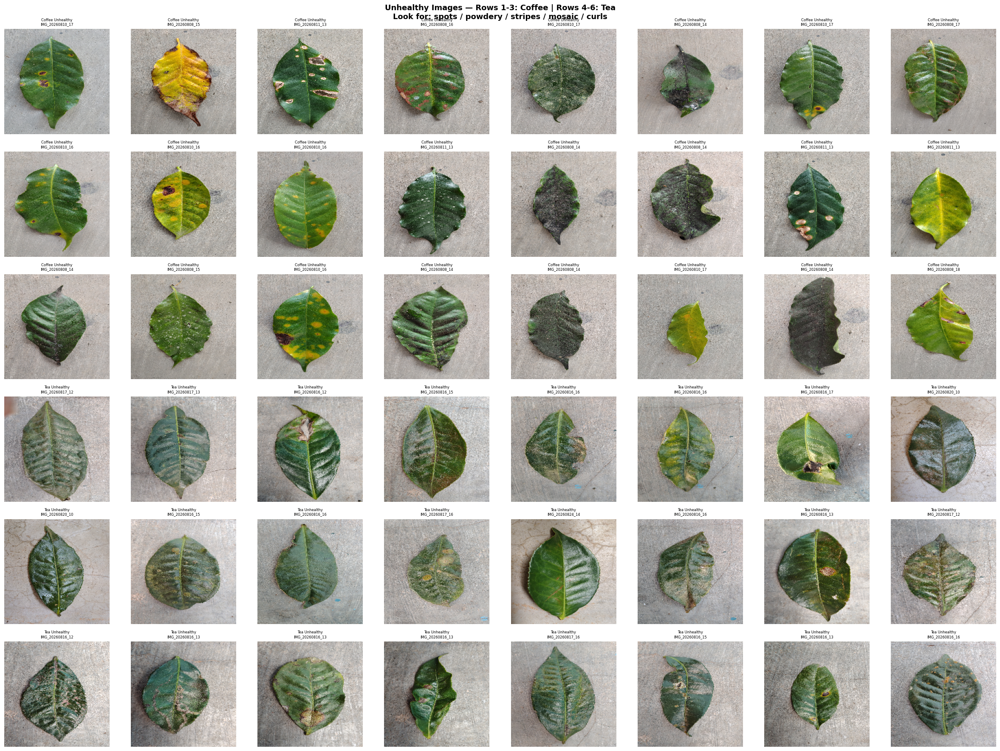

Saved: unhealthy_pattern_check.png


In [48]:
import random
random.seed(42)

fig, axes = plt.subplots(6, 8, figsize=(24, 18))
axes = axes.flatten()

coffee_unhealthy = list((coffee_path / 'UNHEALTHY').glob('*.jpg'))
tea_unhealthy    = list((tea_path    / 'UNHEALTHY').glob('*.jpg'))

coffee_sample = random.sample(coffee_unhealthy, 24)
tea_sample    = random.sample(tea_unhealthy,    24)

for i, img_path in enumerate(coffee_sample):
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (200, 200))
    axes[i].imshow(img)
    axes[i].set_title(f'Coffee Unhealthy\n{img_path.name[:15]}', fontsize=6)
    axes[i].axis('off')

for i, img_path in enumerate(tea_sample):
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (200, 200))
    axes[24 + i].imshow(img)
    axes[24 + i].set_title(f'Tea Unhealthy\n{img_path.name[:15]}', fontsize=6)
    axes[24 + i].axis('off')

plt.suptitle('Unhealthy Images — Rows 1-3: Coffee | Rows 4-6: Tea\nLook for: spots / powdery / stripes / mosaic / curls',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/unhealthy_pattern_check.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: unhealthy_pattern_check.png")

In [50]:
if os.path.exists(DB_PATH):
    os.remove(DB_PATH)

conn = sqlite3.connect(DB_PATH)
conn.row_factory = sqlite3.Row
cursor = conn.cursor()

cursor.execute('''
    CREATE TABLE IF NOT EXISTS knowledge_base (
        id          INTEGER PRIMARY KEY AUTOINCREMENT,
        crop        TEXT NOT NULL,
        disease     TEXT NOT NULL,
        health      TEXT NOT NULL,
        pattern     TEXT,
        colors      TEXT NOT NULL,
        description TEXT,
        treatment   TEXT
    )
''')

diseases = [
    ('coffee', 'Coffee Leaf Rust',           'unhealthy', 'spots',
     'brown,yellow',
     'Fungal disease causing circular yellow-brown spots on upper leaf surface with orange pustules underneath.',
     'Apply copper-based fungicides. Remove infected leaves. Improve air circulation.'),

    ('coffee', 'Coffee Phoma Blight',        'unhealthy', 'spots',
     'brown,black',
     'Fungal disease causing dark brown to black circular necrotic lesions with defined margins.',
     'Apply mancozeb or carbendazim. Prune infected branches. Avoid waterlogging.'),

    ('coffee', 'Coffee Chlorosis',           'unhealthy', 'mosaic',
     'yellow,white',
     'Nutrient deficiency causing irregular yellow-white mottled patches between leaf veins.',
     'Apply chelated iron and magnesium fertilizer. Test soil pH. Improve drainage.'),

    ('coffee', 'Coffee Cercospora Leaf Spot','unhealthy', 'spots',
     'brown,gray',
     'Fungal disease causing circular spots with brown borders and gray centers on leaves.',
     'Apply copper fungicides. Remove infected leaves. Maintain proper plant spacing.'),

    ('coffee', 'Coffee Sooty Mold',          'unhealthy', 'powdery',
     'black,gray',
     'Fungal growth forming black powdery coating across leaf surface due to insect honeydew.',
     'Control insect populations. Wash leaves with soapy water. Improve ventilation.'),

    ('coffee', 'Coffee Bacterial Blight',    'unhealthy', 'spots',
     'brown,black,gray',
     'Bacterial infection causing water-soaked spots that turn brown and black scattered across leaf.',
     'Apply copper bactericides. Avoid overhead irrigation. Remove infected material.'),

    ('coffee', 'Healthy Coffee Leaf',        'healthy',   'none',
     '',
     'Leaf shows no signs of disease. Plant is in good health.',
     'Continue current care. Maintain regular fertilization and irrigation.'),

    ('tea', 'Tea Blister Blight',            'unhealthy', 'powdery',
     'white,gray',
     'Fungal disease causing raised white blister pustules on young tea leaves — powdery white patches on surface.',
     'Apply copper oxychloride. Avoid working in wet conditions. Improve air circulation.'),

    ('tea', 'Tea Red Spot',                  'unhealthy', 'spots',
     'brown,black',
     'Fungal disease causing small reddish-brown circular spots scattered across mature tea leaves.',
     'Apply mancozeb fungicides. Remove infected leaves. Improve plantation drainage.'),

    ('tea', 'Tea Algal Leaf Spot',           'unhealthy', 'spots',
     'gray,white',
     'Algal infection causing raised circular crusty gray-white spots on tea leaf surface.',
     'Apply copper fungicides. Improve air circulation. Reduce shade and humidity.'),

    ('tea', 'Tea Gray Blight',               'unhealthy', 'spots',
     'gray,brown',
     'Fungal disease causing gray-brown necrotic spots that expand and merge across tea leaves.',
     'Apply carbendazim or mancozeb. Remove infected leaves. Maintain plantation hygiene.'),

    ('tea', 'Tea Brown Blight',              'unhealthy', 'spots',
     'brown,black',
     'Fungal disease causing brown water-soaked circular lesions that darken and spread rapidly.',
     'Apply copper-based fungicides immediately. Remove infected branches. Avoid wet conditions.'),

    ('tea', 'Tea White Spot',                'unhealthy', 'spots',
     'white,black',
     'Fungal disease causing circular white spots with dark borders on tea leaves.',
     'Apply hexaconazole fungicide. Remove infected debris. Improve drainage.'),

    ('tea', 'Tea Anthracnose',               'unhealthy', 'spots',
     'brown,black,gray',
     'Fungal disease causing dark sunken circular lesions with yellow halos on tea leaves.',
     'Apply mancozeb or copper fungicides. Prune infected parts. Avoid waterlogging.'),

    ('tea', 'Tea Chlorosis',                 'unhealthy', 'mosaic',
     'yellow,white',
     'Nutrient deficiency causing irregular yellow-white mottled discoloration between leaf veins.',
     'Apply chelated iron or magnesium sulfate. Adjust soil pH. Improve drainage.'),

    ('tea', 'Healthy Tea Leaf',              'healthy',   'none',
     '',
     'Leaf shows no signs of disease. Plant is in good health.',
     'Continue current care. Monitor regularly for early signs of disease.'),
]

cursor.executemany('''
    INSERT INTO knowledge_base
    (crop, disease, health, pattern, colors, description, treatment)
    VALUES (?, ?, ?, ?, ?, ?, ?)
''', diseases)

conn.commit()

cursor.execute('SELECT COUNT(*) FROM knowledge_base')
print(f"KB created: {cursor.fetchone()[0]} diseases")
print(f"\n{'Crop':<10}{'Disease':<30}{'Health':<12}{'Pattern':<12}{'Colors'}")
print("-" * 80)
cursor.execute('SELECT crop, disease, health, pattern, colors FROM knowledge_base')
for row in cursor.fetchall():
    print(f"{row['crop']:<10}{row['disease']:<30}{row['health']:<12}{row['pattern']:<12}{row['colors']}")
conn.close()

KB created: 16 diseases

Crop      Disease                       Health      Pattern     Colors
--------------------------------------------------------------------------------
coffee    Coffee Leaf Rust              unhealthy   spots       brown,yellow
coffee    Coffee Phoma Blight           unhealthy   spots       brown,black
coffee    Coffee Chlorosis              unhealthy   mosaic      yellow,white
coffee    Coffee Cercospora Leaf Spot   unhealthy   spots       brown,gray
coffee    Coffee Sooty Mold             unhealthy   powdery     black,gray
coffee    Coffee Bacterial Blight       unhealthy   spots       brown,black,gray
coffee    Healthy Coffee Leaf           healthy     none        
tea       Tea Blister Blight            unhealthy   powdery     white,gray
tea       Tea Red Spot                  unhealthy   spots       brown,black
tea       Tea Algal Leaf Spot           unhealthy   spots       gray,white
tea       Tea Gray Blight               unhealthy   spots       gray,br

In [51]:
def match_disease(predicted_crop, predicted_health, detected_colors):
    conn = sqlite3.connect(DB_PATH)
    conn.row_factory = sqlite3.Row
    cursor = conn.cursor()
    cursor.execute('SELECT * FROM knowledge_base')
    rows = cursor.fetchall()
    conn.close()

    KB_WEIGHTS  = {'crop': 0.5, 'health': 0.3, 'color': 0.2}
    KB_MIN_SCORE = 0.4

    best_score = 0.0
    best_match = None

    for row in rows:
        score = 0.0

        if predicted_crop.lower() == row['crop'].lower():
            score += KB_WEIGHTS['crop']

        if predicted_health.lower() == row['health'].lower():
            score += KB_WEIGHTS['health']

        row_colors = [c.strip().lower() for c in row['colors'].split(',') if c.strip()]
        if detected_colors and row_colors:
            overlap     = len(set(detected_colors) & set(row_colors))
            color_score = overlap / len(row_colors)
            score += KB_WEIGHTS['color'] * color_score
        elif not detected_colors and not row_colors:
            score += KB_WEIGHTS['color']

        if score > best_score:
            best_score = score
            best_match = row

    if best_score < KB_MIN_SCORE or best_match is None:
        return {
            'disease':     'Condition Not Identified',
            'pattern':     'unknown',
            'description': 'No matching condition found in knowledge base.',
            'treatment':   'Please consult an agricultural expert.',
            'match_score': round(best_score, 4)
        }

    return {
        'disease':     best_match['disease'],
        'pattern':     best_match['pattern'],
        'description': best_match['description'],
        'treatment':   best_match['treatment'],
        'match_score': round(best_score, 4)
    }

random.seed(77)
test_samples_kb = []
for crop_label, crop_dir in [('coffee', coffee_path), ('tea', tea_path)]:
    for health_label in ['HEALTHY', 'UNHEALTHY']:
        cls_dir = crop_dir / health_label
        imgs    = list(cls_dir.glob('*.jpg'))
        picked  = random.sample(imgs, 2)
        for p in picked:
            test_samples_kb.append((str(p), crop_label, health_label.lower()))

print(f"{'#':<3} {'Crop':<8} {'Health':<12} {'Pattern':<10} {'Disease':<28} {'Colors':<30} {'Sev':<10} {'Score'}")
print("-" * 115)

for i, (img_path, actual_crop, actual_health) in enumerate(test_samples_kb):
    img_bgr    = cv2.imread(img_path)
    img_bgr_r  = cv2.resize(img_bgr, (256, 256))
    img_tensor = val_tf(PILImage.open(img_path).convert('RGB')).unsqueeze(0).to(device)

    crop_model.eval()
    health_model.eval()

    with torch.no_grad():
        crop_out  = crop_model(img_tensor)
        crop_prob = torch.softmax(crop_out, dim=1)
        crop_idx  = crop_out.argmax(dim=1).item()
        crop_conf = round(crop_prob[0][crop_idx].item() * 100, 2)
        crop_pred = CROP_CLASSES[crop_idx]
        if crop_conf < 60.0:
            crop_pred = 'crop_not_supported'

        health_out  = health_model(img_tensor)
        health_prob = torch.softmax(health_out, dim=1)
        health_idx  = health_out.argmax(dim=1).item()
        health_conf = round(health_prob[0][health_idx].item() * 100, 2)
        health_pred = HEALTH_CLASSES[health_idx]

    leaf_mask = get_leaf_mask(img_bgr_r)
    detected_colors, disease_mask, severity_pct, severity_label = \
        detect_colors_and_severity(img_bgr_r, leaf_mask)

    kb_result = match_disease(crop_pred, health_pred, detected_colors)

    print(f"{i+1:<3} {crop_pred:<8} {health_pred:<12} {kb_result['pattern']:<10} "
          f"{kb_result['disease']:<28} {str(detected_colors):<30} "
          f"{severity_label:<10} {kb_result['match_score']}")

print("\nFull pipeline with pattern from KB — complete.")

#   Crop     Health       Pattern    Disease                      Colors                         Sev        Score
-------------------------------------------------------------------------------------------------------------------
1   coffee   healthy      none       Healthy Coffee Leaf          ['gray']                       Mild       0.8
2   coffee   healthy      none       Healthy Coffee Leaf          ['black', 'gray']              Mild       0.8
3   coffee   unhealthy    spots      Coffee Leaf Rust             ['brown', 'yellow']            Severe     1.0
4   coffee   unhealthy    powdery    Coffee Sooty Mold            ['black', 'gray']              Mild       1.0
5   tea      healthy      none       Healthy Tea Leaf             ['black', 'white', 'gray']     Severe     0.8
6   tea      healthy      none       Healthy Tea Leaf             ['black', 'gray']              Moderate   0.8
7   tea      unhealthy    powdery    Tea Blister Blight           ['brown', 'black', 'white', 'gra

In [52]:
import torch
import torchvision
import cv2
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import seaborn
import PIL

versions = {
    'torch':         torch.__version__,
    'torchvision':   torchvision.__version__,
    'opencv-python': cv2.__version__,
    'numpy':         np.__version__,
    'pandas':        pd.__version__,
    'scikit-learn':  sklearn.__version__,
    'matplotlib':    matplotlib.__version__,
    'seaborn':       seaborn.__version__,
    'Pillow':        PIL.__version__,
    'groq':          '1.7.0',
}

req_lines = [f"{pkg}=={ver}" for pkg, ver in versions.items()]
req_lines += [
    '',
    'flask==3.0.3',
    'flask-cors==4.0.1',
    'werkzeug==3.0.3',
    'bcrypt==4.1.3',
]

with open('/kaggle/working/requirements.txt', 'w') as f:
    f.write('\n'.join(req_lines))

print("ALL FINAL FILES:")
print("=" * 60)
for f in sorted(Path('/kaggle/working').rglob('*')):
    if f.is_file():
        size = f.stat().st_size / 1e6
        print(f"  {str(f).replace('/kaggle/working/',''):<50} {size:.2f} MB")

ALL FINAL FILES:
  .virtual_documents/__notebook_source__.ipynb       0.08 MB
  class_distribution.png                             0.06 MB
  color_filter_recalibrated.png                      3.87 MB
  color_filter_test.png                              3.58 MB
  crop_class_weights.npy                             0.00 MB
  crop_model_best.pth                                75.20 MB
  crop_model_predictions.png                         7.13 MB
  crop_model_results.png                             0.22 MB
  crop_model_roc.png                                 0.06 MB
  dataset.csv                                        0.46 MB
  dataset_distribution.png                           0.09 MB
  full_pipeline_test.png                             7.36 MB
  health_class_weights.npy                           0.00 MB
  health_model_best.pth                              420.02 MB
  health_model_predictions.png                       7.11 MB
  health_model_results.png                           0.22 MB
  he

In [ ]:
!zip -r model.zip /kaggle/working

  adding: kaggle/working/ (stored 0%)
  adding: kaggle/working/full_pipeline_test.png (deflated 3%)
  adding: kaggle/working/health_model_results.png (deflated 18%)
  adding: kaggle/working/health_model_best.pth

In [ ]:
from IPython.display import FileLink
FileLink(r'model.zip')